# Chapter 7 — Optimization: Gradient Descent and Stochastic Gradient Descent

*Chapter 6 ended with a loss that has no closed-form minimizer and was handled with Newton's method, a method that needs the Hessian and a linear solve at every step. This chapter studies the cheap alternative that powers almost all of modern machine learning: follow the negative gradient. We shall see exactly how fast it converges, why the answer is governed by the same singular values that governed ridge regression, what changes when the gradient is estimated from a few examples, and why stopping early is itself a form of regularization.*

## 7.1 Learning objectives

Every model of the book so far has been defined as the minimizer of a loss. Chapters 1 and 6 could find that minimizer by solving linear equations, or, for the logistic loss, with a few Newton steps. In the chapters that follow (support vector machines, boosting, neural networks) the minimizer has to be computed iteratively, with methods that use only the *gradient* of the loss, because the Hessian is too large to form, or because the loss is a sum over millions of examples. This chapter develops the theory and the practice of these methods on the models that we already understand, where the true minimizer is known and every claim can be checked.

After working through it you will be able to:

1. derive the **gradient** of the least-squares, logistic and softmax losses, verify it by finite differences, and prove that the negative gradient is the direction of steepest descent;
2. define **smoothness** ($L$), **strong convexity** ($\mu$) and the **condition number** $\kappa = L/\mu$, and compute them for the models of Chapter 6;
3. state and prove the **descent lemma**, and from it the convergence of gradient descent: exact formulas on quadratics (with the step-size limit $2/L$), the $O(1/k)$ rate for convex smooth functions, and the linear rate $(1 - \mu/L)^k$ for strongly convex ones;
4. explain why **feature scaling** speeds up the optimization (preconditioning), why **Newton's method** is the ideal preconditioner, and choose a step size automatically with **backtracking line search**;
5. derive **momentum** (heavy ball) and **Nesterov acceleration**, and prove that on quadratics they replace $\kappa$ by $\sqrt\kappa$;
6. explain **stochastic gradient descent**: the unbiased mini-batch gradient, the **noise floor** of a constant step size, the $O(1/k)$ rate of a decreasing step size, and the cost accounting in **epochs**;
7. use SGD in practice: choose the learning rate on a logarithmic grid, and recognize **early stopping** as an implicit form of ridge regularization and gradient descent on separable data as a path to the **maximum-margin** classifier;
8. describe **adaptive methods** (AdaGrad, RMSprop, Adam) and what they fix and do not fix, understand the role of **saddle points** in non-convex problems, and choose an optimizer for a given problem.

**Prerequisites.** Chapters 1 to 6. In particular the normal equations (Section 1.6), the eigendecomposition and the effect of feature scales (Sections 2.3.7 and 2.7.1), the conditioning of least squares (Section 6.2.3), the singular-value view of ridge (Section 6.3.2), and the logistic loss, Newton's method and separable data (Sections 6.4.2 to 6.4.4).

:::{admonition} A word about the data in this chapter
:class: note
The experiments use real data sets, all shipped with scikit-learn: **Diabetes** (least squares), **Breast Cancer** (logistic regression), **Digits** (softmax regression) and two classes of **Iris** (a separable problem). Since the theory of this chapter is about *optimization*, the target of each experiment is the exact minimum of the loss, which we compute once with Newton's method or with L-BFGS and call $f^\ast$; the plots then show the **suboptimality** $f(\mathbf{w}_k) - f^\ast$, which can be measured exactly. Only two constructions are not data: the small quadratic functions used to draw the geometry of gradient descent (Section 7.3.2), and two classical test functions of non-convex optimization (Section 7.9). Both are flagged where they appear.
:::

### Setting up this notebook

As in the previous chapters, the next two cells print the versions of the libraries and define the plotting style and the random seed.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit, logsumexp
from sklearn.datasets import load_breast_cancer, load_diabetes, load_digits, load_iris
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 7.2 The problem, the gradient and the geometry

### 7.2.1 What we minimize, and the direction of steepest descent

In this chapter every model is a vector of parameters $\mathbf{w} \in \mathbb{R}^p$ (the intercept included: we write $\mathbf{w}$ for all the parameters, where Chapter 6 distinguished $b$ and $\mathbf{w}$) and every training problem has the form

$$
\min_{\mathbf{w} \in \mathbb{R}^p} f(\mathbf{w}),
\qquad
f(\mathbf{w}) = \frac1n\sum_{i=1}^n \ell_i(\mathbf{w}) + \frac\lambda2\lVert\mathbf{w}\rVert^2,
$$

the average of a loss $\ell_i$ per training example plus a ridge penalty. The three losses of Chapter 6 give three objectives, and each gradient has the same shape, *features times residual*:

| Model | $\ell_i(\mathbf{w})$ | $\nabla f(\mathbf{w})$ (no penalty) |
|---|---|---|
| Least squares | $\tfrac12(\mathbf{x}_i^\top\mathbf{w} - y_i)^2$ | $\frac1n\mathbf{X}^\top(\mathbf{X}\mathbf{w} - \mathbf{y})$ |
| Logistic regression | $\log(1 + e^{\mathbf{x}_i^\top\mathbf{w}}) - y_i\,\mathbf{x}_i^\top\mathbf{w}$ | $\frac1n\mathbf{X}^\top(\mathbf{p} - \mathbf{y})$, $\ p_i = \sigma(\mathbf{x}_i^\top\mathbf{w})$ |
| Softmax regression | $-\log p_{i,y_i}$ | $\frac1n(\mathbf{P} - \mathbf{Y})^\top\mathbf{X}$ |

(Least squares with the factor $\frac12$ is the loss of Chapter 6 divided by $n$; the logistic and softmax gradients are Proposition 6.9 and Exercise 6.5; the penalty adds $\lambda\mathbf{w}$ to each gradient.) The residual $\mathbf{X}\mathbf{w} - \mathbf{y}$, or $\mathbf{p} - \mathbf{y}$, says how wrong the model is on each example, and the gradient weighs the features by this error.

Why is the *negative gradient* the direction to move? Because, among all the directions of the same length, it is the one along which the function decreases fastest.

:::{admonition} Proposition 7.1 (steepest descent)
:class: tip
Let $f$ be differentiable at $\mathbf{w}$ with $\nabla f(\mathbf{w}) \neq \mathbf{0}$. For every unit vector $\mathbf{u}$, the directional derivative satisfies
$$
-\lVert\nabla f(\mathbf{w})\rVert \le \nabla f(\mathbf{w})^\top\mathbf{u} \le \lVert\nabla f(\mathbf{w})\rVert,
$$
and the lower bound is attained only by $\mathbf{u} = -\nabla f(\mathbf{w})/\lVert\nabla f(\mathbf{w})\rVert$.
:::

:::{admonition} Proof
:class: dropdown
This is the Cauchy–Schwarz inequality, $\lvert\mathbf{g}^\top\mathbf{u}\rvert \le \lVert\mathbf{g}\rVert\,\lVert\mathbf{u}\rVert$, with equality if and only if $\mathbf{u}$ is a multiple of $\mathbf{g}$. For $\mathbf{u} = -\mathbf{g}/\lVert\mathbf{g}\rVert$ the directional derivative equals $-\lVert\mathbf{g}\rVert$. $\square$
:::

The statement is about an infinitesimal step. How far to go along $-\nabla f$ is the whole subject of this chapter. **Gradient descent** (GD) chooses a number $\eta > 0$, the **step size** or **learning rate**, and iterates

$$
\mathbf{w}_{k+1} = \mathbf{w}_k - \eta\,\nabla f(\mathbf{w}_k).
$$

Before using a gradient, verify it. The central finite difference $\big(f(\mathbf{w} + h\mathbf{e}_j) - f(\mathbf{w} - h\mathbf{e}_j)\big)/(2h)$ approximates the $j$-th component with an error of order $h^2$; it costs two evaluations of $f$ per coordinate, so it is a testing tool and not an algorithm. The next cell loads the Diabetes data with the split used in Chapter 6 (331 training patients, standardized with the training statistics, centered target), checks the least-squares gradient and the claim of Proposition 7.1 on 100,000 random directions.

In [3]:
diab = load_diabetes(scaled=False)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(diab.data, diab.target, test_size=0.25, random_state=SEED)
scaler_d = StandardScaler().fit(Xd_tr)
Zd, Zd_te = scaler_d.transform(Xd_tr), scaler_d.transform(Xd_te)
n_d = len(yd_tr)
yd_mean = yd_tr.mean()
yd_c = yd_tr - yd_mean                       # centered target: no intercept needed
print(f"Diabetes: {n_d} training patients, {Zd.shape[1]} features")


def ls_objective(w, A, yc, lam):
    """Ridge least squares f(w) = (1/2n)||A w - yc||^2 + (lam/2)||w||^2 and its gradient."""
    r = A @ w - yc
    return 0.5 * np.mean(r**2) + 0.5 * lam * w @ w, A.T @ r / len(yc) + lam * w


def central_difference(f, w, h=1e-6):
    g = np.zeros_like(w)
    for j in range(len(w)):
        e = np.zeros_like(w)
        e[j] = h
        g[j] = (f(w + e) - f(w - e)) / (2 * h)
    return g


rng = np.random.default_rng(SEED)
w_try = rng.normal(size=Zd.shape[1])
f_try, g_try = ls_objective(w_try, Zd, yd_c, lam=0.1)
g_fd = central_difference(lambda w: ls_objective(w, Zd, yd_c, 0.1)[0], w_try)
print(f"relative error of the analytic gradient: {np.linalg.norm(g_try - g_fd) / np.linalg.norm(g_try):.1e}")

# Proposition 7.1: no unit direction beats -g/||g||
U = rng.normal(size=(100_000, len(w_try)))
U /= np.linalg.norm(U, axis=1, keepdims=True)
print(f"smallest directional derivative among 100,000 random unit directions: {(U @ g_try).min():.2f}")
print(f"-||g||, the value for the steepest direction                        : {-np.linalg.norm(g_try):.2f}")

Diabetes: 331 training patients, 10 features
relative error of the analytic gradient: 8.3e-09
smallest directional derivative among 100,000 random unit directions: -88.71
-||g||, the value for the steepest direction                        : -95.41


### 7.2.2 Smoothness, strong convexity and the condition number

How large a step can we afford? That depends on how fast the gradient itself changes, that is on the curvature. Two numbers describe it.

**Definition.** A differentiable function $f$ is **$L$-smooth** if its gradient is $L$-Lipschitz: $\lVert\nabla f(\mathbf{x}) - \nabla f(\mathbf{y})\rVert \le L\lVert\mathbf{x} - \mathbf{y}\rVert$ for all $\mathbf{x}, \mathbf{y}$. It is **$\mu$-strongly convex** if $f(\mathbf{y}) \ge f(\mathbf{x}) + \nabla f(\mathbf{x})^\top(\mathbf{y} - \mathbf{x}) + \frac\mu2\lVert\mathbf{y} - \mathbf{x}\rVert^2$ for all $\mathbf{x}, \mathbf{y}$ (the function lies above its tangent plane by at least a parabola). The ratio

$$
\kappa = \frac{L}{\mu} \ge 1
$$

is the **condition number**.

For a twice differentiable function both properties are statements about the eigenvalues of the Hessian: $f$ is $L$-smooth and $\mu$-strongly convex if and only if

$$
\mu\mathbf{I} \preceq \nabla^2 f(\mathbf{w}) \preceq L\mathbf{I}\qquad\text{for all } \mathbf{w}.
$$

(One direction in a line: $\nabla f(\mathbf{x}) - \nabla f(\mathbf{y}) = \bar{\mathbf{H}}(\mathbf{x} - \mathbf{y})$ with $\bar{\mathbf{H}} = \int_0^1\nabla^2 f(\mathbf{y} + t(\mathbf{x} - \mathbf{y}))\,dt$, a symmetric matrix whose eigenvalues lie in $[\mu, L]$, so $\lVert\nabla f(\mathbf{x}) - \nabla f(\mathbf{y})\rVert \le L\lVert\mathbf{x} - \mathbf{y}\rVert$.) For the least-squares objective of Chapter 6 the Hessian does not depend on $\mathbf{w}$:

$$
\nabla^2 f = \mathbf{H} = \frac1n\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I},
\qquad
L = \frac{\sigma_{\max}^2}{n} + \lambda,\quad
\mu = \frac{\sigma_{\min}^2}{n} + \lambda,
$$

where $\sigma_{\max}$ and $\sigma_{\min}$ are the extreme singular values of $\mathbf{X}$ (Section 6.3.2). The same singular values that decided how much ridge shrinks each direction decide how curved the loss is in each direction, and a ridge penalty adds $\lambda$ to *all* the curvatures, which lowers the condition number. The next cell computes $L$, $\mu$ and $\kappa$ for the Diabetes problem in three situations.

In [4]:
def hessian_spectrum(A, lam):
    """Eigenvalues (descending) of H = A^T A / n + lam I, with the columns of A centered."""
    Ac = A - A.mean(axis=0)
    return np.linalg.eigvalsh(Ac.T @ Ac / len(A) + lam * np.eye(A.shape[1]))[::-1]


cases = {
    "raw units, lambda = 0": hessian_spectrum(Xd_tr, 0.0),
    "standardized, lambda = 0": hessian_spectrum(Zd, 0.0),
    "standardized, lambda = 0.1": hessian_spectrum(Zd, 0.1),
    "standardized, lambda = 1": hessian_spectrum(Zd, 1.0),
}
cond_table = pd.DataFrame(
    {name: {"L": ev[0], "mu": ev[-1], "kappa": ev[0] / ev[-1]} for name, ev in cases.items()}
).T
print(cond_table.to_string(formatters={"L": "{:.4g}".format, "mu": "{:.4g}".format, "kappa": "{:.4g}".format}))

                               L       mu     kappa
raw units, lambda = 0       2092  0.02814 7.434e+04
standardized, lambda = 0   3.919 0.009379     417.8
standardized, lambda = 0.1 4.019   0.1094     36.74
standardized, lambda = 1   4.919    1.009     4.873


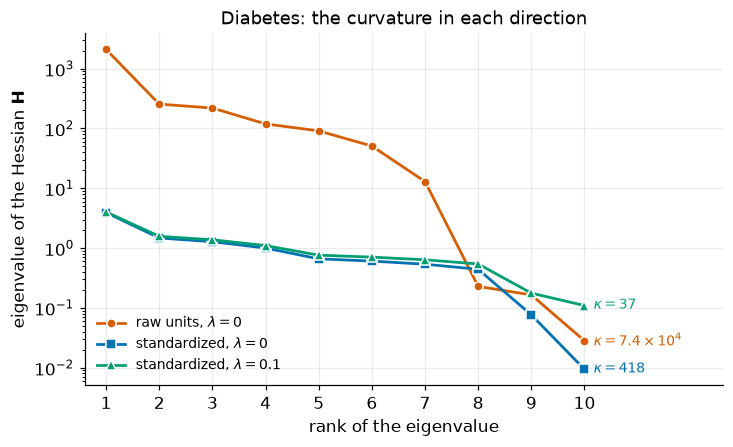

In [5]:
# Figure 7.1 — the spectrum of the Hessian decides the condition number
def figure_7_1():
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ranks = np.arange(1, 11)
    styles = [("raw units, lambda = 0", VERMILION, "o", "raw units, $\\lambda = 0$"),
              ("standardized, lambda = 0", BLUE, "s", "standardized, $\\lambda = 0$"),
              ("standardized, lambda = 0.1", GREEN, "^", "standardized, $\\lambda = 0.1$")]
    for key, color, marker, label in styles:
        ev = cases[key]
        ax.plot(ranks, ev, marker=marker, color=color, lw=1.8, ms=6, mec="white", label=label)
        kap = ev[0] / ev[-1]
        txt = rf"$\kappa = {kap:.0f}$" if kap < 1e3 else rf"$\kappa = {kap / 1e4:.1f}\times 10^4$"
        ax.annotate(txt, (10, ev[-1]), textcoords="offset points", xytext=(6, 0), va="center", fontsize=9, color=color)
    ax.set_yscale("log")
    ax.set(xlabel="rank of the eigenvalue", ylabel=r"eigenvalue of the Hessian $\mathbf{H}$",
           xticks=ranks, xlim=(0.6, 12.6), title="Diabetes: the curvature in each direction")
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_7_1()

The conditioning of the raw problem is $\kappa \approx 7 \cdot 10^4$: the curvature in the steepest direction is $2092$ and in the flattest only $0.028$. Almost all of it is an accident of units (the columns of the raw data are measured in years, kilograms, milligrams per decilitre, and so on); **standardizing the features** brings $\kappa$ down to $418$ without changing the model at all, and the remaining ill-conditioning is the collinearity of the blood-serum variables that Section 6.2.3 diagnosed. A ridge penalty of $\lambda = 0.1$ lowers it to $37$ and $\lambda = 1$ to $4.9$. We shall see in the next sections that $\kappa$ is, up to constants, the number of gradient steps that a first-order method needs per factor of $e$ of accuracy.

For the logistic loss the Hessian $\frac1n\mathbf{X}^\top\mathbf{S}\mathbf{X} + \lambda\mathbf{I}$ depends on $\mathbf{w}$ through the weights $s_i = p_i(1 - p_i) \in (0, \tfrac14]$ (Section 6.4.2). Since $s_i \le \tfrac14$, the loss is $L$-smooth *globally* with $L = \sigma_{\max}^2/(4n) + \lambda$, a bound that we shall find to be very pessimistic near the solution (Section 7.3.4). Strong convexity holds only with the constant $\mu = \lambda$ plus a term that decays to zero as the probabilities approach 0 and 1; for this reason the ridge penalty matters for the optimization as much as for the statistics.

## 7.3 Gradient descent

### 7.3.1 The descent lemma

The workhorse of every convergence proof in this chapter is the following inequality. It says that an $L$-smooth function lies *below* a parabola built on its tangent plane, which is exactly what we need to know that a small step cannot overshoot too much.

:::{admonition} Proposition 7.2 (descent lemma)
:class: tip
If $f$ is $L$-smooth, then for all $\mathbf{x}, \mathbf{y}$,
$$
f(\mathbf{y}) \le f(\mathbf{x}) + \nabla f(\mathbf{x})^\top(\mathbf{y} - \mathbf{x}) + \frac L2\lVert\mathbf{y} - \mathbf{x}\rVert^2 .
$$
Consequently a gradient step $\mathbf{x}^+ = \mathbf{x} - \eta\nabla f(\mathbf{x})$ satisfies
$$
f(\mathbf{x}^+) \le f(\mathbf{x}) - \eta\Big(1 - \frac{L\eta}{2}\Big)\lVert\nabla f(\mathbf{x})\rVert^2 ,
$$
so the function decreases whenever $0 < \eta < 2/L$, and for $\eta \le 1/L$ it decreases by at least $\frac\eta2\lVert\nabla f(\mathbf{x})\rVert^2$.
:::

:::{admonition} Proof
:class: dropdown
By the fundamental theorem of calculus along the segment from $\mathbf{x}$ to $\mathbf{y}$,
$$
f(\mathbf{y}) - f(\mathbf{x}) - \nabla f(\mathbf{x})^\top(\mathbf{y} - \mathbf{x})
= \int_0^1\big(\nabla f(\mathbf{x} + t(\mathbf{y} - \mathbf{x})) - \nabla f(\mathbf{x})\big)^\top(\mathbf{y} - \mathbf{x})\,dt .
$$
By Cauchy–Schwarz and the Lipschitz property, the integrand is at most $Lt\lVert\mathbf{y} - \mathbf{x}\rVert^2$, and $\int_0^1 Lt\,dt = L/2$. For the gradient step put $\mathbf{y} = \mathbf{x} - \eta\nabla f(\mathbf{x})$: the linear term is $-\eta\lVert\nabla f\rVert^2$ and the quadratic term is $\frac{L\eta^2}{2}\lVert\nabla f\rVert^2$. If $\eta \le 1/L$ then $1 - L\eta/2 \ge \frac12$. $\square$
:::

The lemma already explains the limit that we shall meet in every experiment: the guarantee of decrease disappears at $\eta = 2/L$.

### 7.3.2 Gradient descent on a quadratic

The quadratic $f(\mathbf{w}) = \frac12\mathbf{w}^\top\mathbf{H}\mathbf{w} - \mathbf{b}^\top\mathbf{w}$ with $\mathbf{H} \succ 0$ is both the least-squares objective and the second-order Taylor model of any smooth loss near its minimum, so it is the right place to understand GD exactly. Its gradient is $\mathbf{H}\mathbf{w} - \mathbf{b}$ and its minimizer is $\mathbf{w}^\ast = \mathbf{H}^{-1}\mathbf{b}$.

:::{admonition} Theorem 7.3 (gradient descent on a quadratic)
:class: tip
Let $\mathbf{H} = \mathbf{V}\boldsymbol\Lambda\mathbf{V}^\top$ have eigenvalues $\mu = \lambda_p \le \dots \le \lambda_1 = L$ (all positive) and let $c_j = \mathbf{v}_j^\top(\mathbf{w}_0 - \mathbf{w}^\ast)$. Gradient descent with step size $\eta$ produces
$$
\mathbf{v}_j^\top(\mathbf{w}_k - \mathbf{w}^\ast) = (1 - \eta\lambda_j)^k\,c_j,
\qquad
f(\mathbf{w}_k) - f(\mathbf{w}^\ast) = \frac12\sum_j\lambda_j(1 - \eta\lambda_j)^{2k}c_j^2 .
$$
Hence:

1. $\mathbf{w}_k \to \mathbf{w}^\ast$ from every starting point if and only if $0 < \eta < 2/L$; if $\eta > 2/L$ the iterates diverge from every starting point with $c_1 \ne 0$.
2. For $0 < \eta < 2/L$, $\lVert\mathbf{w}_k - \mathbf{w}^\ast\rVert \le \rho(\eta)^k\lVert\mathbf{w}_0 - \mathbf{w}^\ast\rVert$ with $\rho(\eta) = \max\{\lvert 1 - \eta\mu\rvert, \lvert 1 - \eta L\rvert\}$, and this is the best possible constant.
3. The best step size is $\eta^\ast = 2/(L + \mu)$, with $\rho(\eta^\ast) = \dfrac{\kappa - 1}{\kappa + 1}$. With $\eta = 1/L$ the rate is $\rho = 1 - 1/\kappa$.
4. To reduce the error by a factor $\varepsilon$ one needs at most $\kappa\ln(1/\varepsilon)$ iterations with $\eta = 1/L$ and at most $\frac\kappa2\ln(1/\varepsilon)$ with $\eta^\ast$.
:::

:::{admonition} Proof
:class: dropdown
The gradient is $\mathbf{H}(\mathbf{w} - \mathbf{w}^\ast)$, so with $\mathbf{e}_k = \mathbf{w}_k - \mathbf{w}^\ast$ the iteration is $\mathbf{e}_{k+1} = (\mathbf{I} - \eta\mathbf{H})\mathbf{e}_k$. In the eigenbasis of $\mathbf{H}$ each coordinate evolves on its own, $\mathbf{v}_j^\top\mathbf{e}_{k+1} = (1 - \eta\lambda_j)\mathbf{v}_j^\top\mathbf{e}_k$, which gives the formula; the value formula follows from $f(\mathbf{w}) - f(\mathbf{w}^\ast) = \frac12\mathbf{e}^\top\mathbf{H}\mathbf{e}$.

(1) The coordinate $j$ tends to zero for every $c_j$ if and only if $\lvert 1 - \eta\lambda_j\rvert < 1$, that is $0 < \eta < 2/\lambda_j$. All the coordinates converge if and only if $\eta < 2/\lambda_1 = 2/L$. If $\eta > 2/L$ then $\lvert 1 - \eta L\rvert > 1$ and the first coordinate grows geometrically.

(2) $\lVert\mathbf{e}_k\rVert^2 = \sum_j(1 - \eta\lambda_j)^{2k}c_j^2 \le \max_j\lvert 1 - \eta\lambda_j\rvert^{2k}\lVert\mathbf{e}_0\rVert^2$. The function $\lambda \mapsto \lvert 1 - \eta\lambda\rvert$ is convex, so its maximum over $[\mu, L]$ is attained at an endpoint. The bound is attained when $\mathbf{e}_0$ is along the corresponding eigenvector.

(3) The function $\eta \mapsto \max\{\lvert 1 - \eta\mu\rvert, \lvert 1 - \eta L\rvert\}$ decreases while $1 - \eta\mu$ dominates and increases afterwards; the minimum is where $1 - \eta\mu = \eta L - 1$, that is $\eta = 2/(L + \mu)$, and then $\rho = 1 - 2\mu/(L + \mu) = (L - \mu)/(L + \mu)$.

(4) We need $\rho^k \le \varepsilon$, that is $k \ge \ln(1/\varepsilon)/\ln(1/\rho)$. For $\rho = 1 - 1/\kappa$, $\ln(1/\rho) \ge 1/\kappa$. For $\rho = (\kappa - 1)/(\kappa + 1)$, $\ln(1/\rho) = 2\,\mathrm{artanh}(1/\kappa) \ge 2/\kappa$. $\square$
:::

Three consequences are worth keeping in mind. First, **the step size has a hard ceiling** that depends only on the largest curvature, $2/L$; the *smallest* curvature, on the contrary, decides how long the iteration takes. Second, **GD is a filter**: after $k$ steps the component of the error along the $j$-th eigenvector has been multiplied by $(1 - \eta\lambda_j)^k$, so the directions of high curvature converge first and the flat directions last. Section 7.7.2 turns this observation into a statement about regularization. Third, the best achievable rate $(\kappa - 1)/(\kappa + 1)$ is close to $1$ when $\kappa$ is large: *no choice of step size* can rescue an ill-conditioned problem, which is the motivation for Sections 7.4 and 7.5.

### Worked example 7.1 — gradient descent on $f(\mathbf{w}) = \frac12(w_1^2 + 10\,w_2^2)$

*(This is a constructed function, chosen to make the arithmetic exact.)* Here $\mathbf{H} = \mathrm{diag}(1, 10)$, so $\mu = 1$, $L = 10$, $\kappa = 10$, $\mathbf{w}^\ast = \mathbf{0}$, and we start from $\mathbf{w}_0 = (10, 1.5)$. By Theorem 7.3 the coordinates evolve independently, $w_{1,k} = (1 - \eta)^k\cdot 10$ and $w_{2,k} = (1 - 10\eta)^k\cdot 1.5$.

- *Step size $\eta = 1/L = 0.1$.* The second factor is $1 - 10\cdot 0.1 = 0$: the steep coordinate is annihilated in a single step, and the iteration then creeps along the flat coordinate with factor $0.9$. To reduce the error by $10^{-6}$ we need $k \ge \ln 10^6/\ln(1/0.9) = 13.82/0.1054 = 131.1$, that is $132$ iterations.
- *Best step size $\eta^\ast = 2/11 = 0.1818$.* The factors are $9/11 = 0.818$ and $-9/11$: both coordinates shrink at the same rate, the second one changing sign at every step (zigzag). The rate is $\rho = (\kappa - 1)/(\kappa + 1) = 9/11$ and $k \ge 13.82/\ln(11/9) = 13.82/0.2007 = 68.9$, that is $69$ iterations, half as many.
- *Step size $\eta = 0.05$* (small and safe): factors $0.95$ and $0.5$; the rate is $0.95$ and $270$ iterations are needed. A step that is too small wastes iterations.
- *Step size $\eta = 0.19 = 1.9/L$* (just below the ceiling $0.2$): factors $0.81$ and $-0.9$; the steep coordinate oscillates and decays slowly, $\rho = 0.9$; the bound predicts $131$ iterations and the iteration needs $114$ (the oscillating coordinate starts at $1.5$ and not at $10$, so the bound is not attained). Beyond $\eta = 0.2$ the second coordinate is multiplied by a number smaller than $-1$ at every step and the iteration diverges.

In [6]:
H_toy = np.diag([1.0, 10.0])
w0_toy = np.array([10.0, 1.5])
L_toy, mu_toy = 10.0, 1.0
rows = []
for eta in [0.05, 0.1, 2 / 11, 0.19, 0.21]:
    rho = max(abs(1 - eta * mu_toy), abs(1 - eta * L_toy))
    w = w0_toy.copy()
    k_hit = None
    with np.errstate(over="ignore", invalid="ignore"):
        for k in range(1, 2001):
            w = w - eta * (H_toy @ w)
            if np.linalg.norm(w) < 1e-6 * np.linalg.norm(w0_toy):
                k_hit = k
                break
    pred = np.log(1e6) / np.log(1 / rho) if rho < 1 else np.inf
    rows.append({"eta": eta, "rho": rho, "predicted k": pred, "measured k": k_hit if k_hit else "diverges"})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

   eta    rho  predicted k measured k
  0.05   0.95        269.3        270
   0.1    0.9        131.1        132
0.1818 0.8182        68.85         69
  0.19    0.9        131.1        114
  0.21    1.1          inf   diverges


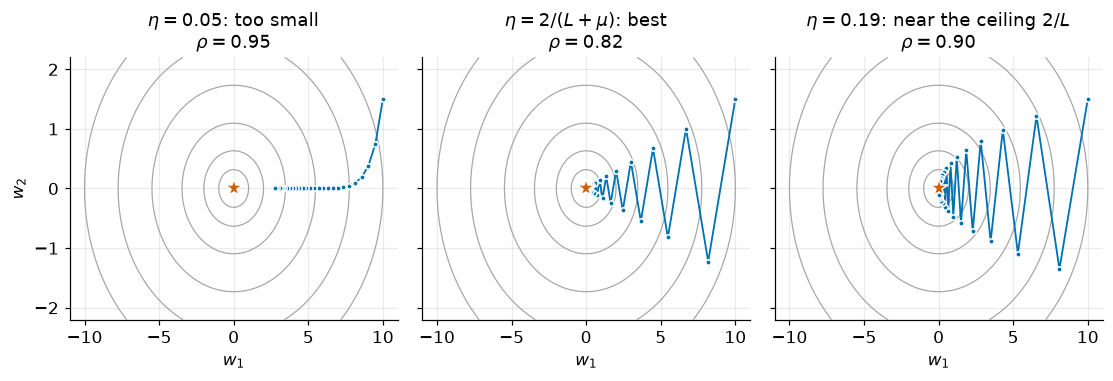

In [7]:
# Figure 7.2 — gradient descent on the quadratic of Worked example 7.1 (a constructed function)
def figure_7_2():
    fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.6), sharey=True)
    g1, g2 = np.meshgrid(np.linspace(-11, 11, 300), np.linspace(-2.2, 2.2, 300))
    F = 0.5 * (g1**2 + 10 * g2**2)
    for ax, eta, title in zip(axes, [0.05, 2 / 11, 0.19],
                              [r"$\eta = 0.05$: too small", r"$\eta = 2/(L+\mu)$: best", r"$\eta = 0.19$: near the ceiling $2/L$"]):
        path = [w0_toy]
        for _ in range(25):
            path.append(path[-1] - eta * (H_toy @ path[-1]))
        path = np.array(path)
        ax.contour(g1, g2, F, levels=[0.5, 2, 6, 15, 30, 50], colors="0.65", linewidths=0.8)
        ax.plot(path[:, 0], path[:, 1], "-o", color=BLUE, ms=3.5, lw=1.2, mec="white")
        ax.plot(0, 0, "*", color=VERMILION, ms=12, mec="white")
        rho = max(abs(1 - eta), abs(1 - 10 * eta))
        ax.set(title=title + f"\n$\\rho = {rho:.2f}$", xlabel="$w_1$", xlim=(-11, 11), ylim=(-2.2, 2.2))
    axes[0].set_ylabel("$w_2$")
    fig.tight_layout()
    plt.show()


figure_7_2()

Now the same measurements on a real problem. The least-squares objective of the standardized Diabetes data with $\lambda = 0$ has $L = 3.92$, $\mu = 0.0094$ and $\kappa = 418$ (Section 7.2.2). We run gradient descent from $\mathbf{w}_0 = \mathbf{0}$ with four step sizes: the "safe" $1/L$, the optimal $2/(L + \mu)$, a step just below the ceiling, $1.9/L$, and one just above, $2.1/L$. For each we compare the number of iterations needed to reduce the distance to $\mathbf{w}^\ast$ by a factor $10^{-6}$ with the prediction $\ln(10^6)/\ln(1/\rho)$ of Theorem 7.3.

In [8]:
H_d = Zd.T @ Zd / n_d                      # lambda = 0
b_d = Zd.T @ yd_c / n_d
w_star_d = np.linalg.solve(H_d, b_d)
ev_d = np.linalg.eigvalsh(H_d)
L_d, mu_d = ev_d[-1], ev_d[0]
kappa_d = L_d / mu_d
print(f"L = {L_d:.4f}, mu = {mu_d:.5f}, kappa = {kappa_d:.1f}, kappa*ln(10^6) = {kappa_d * np.log(1e6):.0f}")


def gd_quadratic(H, b, w0, eta, iters, w_star):
    """Distance ||w_k - w*|| for k = 0..iters (gradient descent on 1/2 w'Hw - b'w)."""
    w, errs = w0.copy(), np.empty(iters + 1)
    errs[0] = np.linalg.norm(w - w_star)
    with np.errstate(over="ignore", invalid="ignore"):
        for k in range(iters):
            w = w - eta * (H @ w - b)
            errs[k + 1] = np.linalg.norm(w - w_star)
    return errs


rules = {"1/L": 1 / L_d, "2/(L+mu)": 2 / (L_d + mu_d), "1.9/L": 1.9 / L_d, "2.1/L": 2.1 / L_d}
err_curves, rows = {}, []
for name, eta in rules.items():
    errs = gd_quadratic(H_d, b_d, np.zeros(len(b_d)), eta, 20_000, w_star_d)
    err_curves[name] = errs
    rho = max(abs(1 - eta * mu_d), abs(1 - eta * L_d))
    hit = np.flatnonzero(errs < 1e-6 * errs[0])
    rows.append({"step size": name, "eta": eta, "rho": rho,
                 "predicted iterations": np.log(1e6) / np.log(1 / rho) if rho < 1 else np.inf,
                 "measured iterations": int(hit[0]) if len(hit) else "diverges"})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.5g}"))

L = 3.9188, mu = 0.00938, kappa = 417.8, kappa*ln(10^6) = 5773


step size     eta     rho  predicted iterations measured iterations
      1/L 0.25518 0.99761                5765.8                5677
 2/(L+mu) 0.50914 0.99522                2886.3                2856
    1.9/L 0.48484 0.99545                3031.3                2985
    2.1/L 0.53588     1.1                   inf            diverges


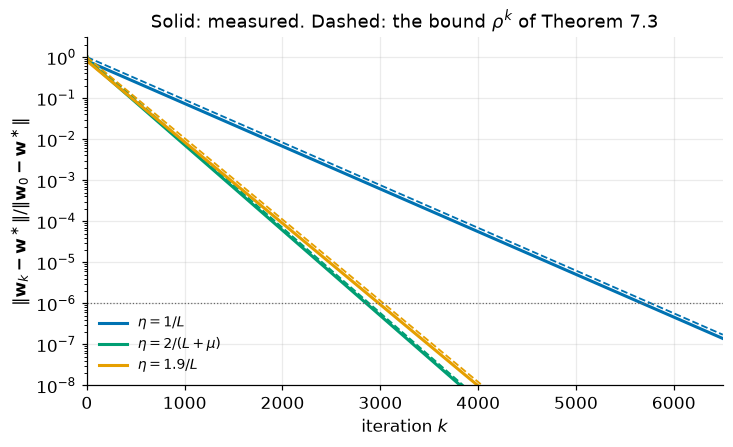

In [9]:
# Figure 7.3 — measured error and the bound rho^k, Diabetes least squares (lambda = 0)
def figure_7_3():
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ks = np.arange(20_001)
    for (name, color, label) in [("1/L", BLUE, r"$\eta = 1/L$"), ("2/(L+mu)", GREEN, r"$\eta = 2/(L+\mu)$"),
                                 ("1.9/L", ORANGE, r"$\eta = 1.9/L$")]:
        eta = rules[name]
        rho = max(abs(1 - eta * mu_d), abs(1 - eta * L_d))
        rel = err_curves[name] / err_curves[name][0]
        ax.plot(ks, rel, color=color, lw=2, label=label)
        ax.plot(ks, rho**ks, color=color, lw=1.2, ls="--")
    ax.axhline(1e-6, color="0.4", lw=0.8, ls=":")
    ax.set(yscale="log", xlim=(0, 6500), ylim=(1e-8, 3),
           xlabel="iteration $k$", ylabel=r"$\|\mathbf{w}_k - \mathbf{w}^\ast\| / \|\mathbf{w}_0 - \mathbf{w}^\ast\|$",
           title="Solid: measured. Dashed: the bound $\\rho^k$ of Theorem 7.3")
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_7_3()

### 7.3.3 Convergence for convex and strongly convex functions

Real losses are not quadratic, but the descent lemma lets us prove two guarantees that hold for every convex $L$-smooth function. The first needs nothing beyond convexity and gives a *sublinear* rate; the second adds strong convexity and gives a *linear* (geometric) rate, in the same form as for quadratics.

:::{admonition} Theorem 7.4 (gradient descent, convex case)
:class: tip
Let $f$ be convex and $L$-smooth with a minimizer $\mathbf{w}^\ast$, and let $0 < \eta \le 1/L$. Then gradient descent satisfies, for every $k \ge 1$,
$$
f(\mathbf{w}_k) - f(\mathbf{w}^\ast) \le \frac{\lVert\mathbf{w}_0 - \mathbf{w}^\ast\rVert^2}{2\eta k}.
$$
:::

:::{admonition} Proof
:class: dropdown
Write $\mathbf{g}_k = \nabla f(\mathbf{w}_k)$. By the descent lemma (Proposition 7.2), $f(\mathbf{w}_{k+1}) \le f(\mathbf{w}_k) - \frac\eta2\lVert\mathbf{g}_k\rVert^2$, and by convexity $f(\mathbf{w}_k) \le f(\mathbf{w}^\ast) + \mathbf{g}_k^\top(\mathbf{w}_k - \mathbf{w}^\ast)$. Combining,
$$
f(\mathbf{w}_{k+1}) - f(\mathbf{w}^\ast) \le \mathbf{g}_k^\top(\mathbf{w}_k - \mathbf{w}^\ast) - \frac\eta2\lVert\mathbf{g}_k\rVert^2
= \frac1{2\eta}\Big(\lVert\mathbf{w}_k - \mathbf{w}^\ast\rVert^2 - \lVert\mathbf{w}_k - \eta\mathbf{g}_k - \mathbf{w}^\ast\rVert^2\Big),
$$
where the identity is obtained by expanding $\lVert\mathbf{a} - \eta\mathbf{g}\rVert^2 = \lVert\mathbf{a}\rVert^2 - 2\eta\,\mathbf{g}^\top\mathbf{a} + \eta^2\lVert\mathbf{g}\rVert^2$ with $\mathbf{a} = \mathbf{w}_k - \mathbf{w}^\ast$. The last norm is $\lVert\mathbf{w}_{k+1} - \mathbf{w}^\ast\rVert^2$. Summing over $k = 0, \dots, K - 1$ the right-hand side telescopes:
$$
\sum_{k=1}^{K}\big(f(\mathbf{w}_k) - f(\mathbf{w}^\ast)\big) \le \frac{\lVert\mathbf{w}_0 - \mathbf{w}^\ast\rVert^2 - \lVert\mathbf{w}_K - \mathbf{w}^\ast\rVert^2}{2\eta} \le \frac{\lVert\mathbf{w}_0 - \mathbf{w}^\ast\rVert^2}{2\eta}.
$$
Since $f(\mathbf{w}_k)$ is non-increasing, the last term of the sum is the smallest, and $K\,(f(\mathbf{w}_K) - f(\mathbf{w}^\ast))$ is at most the sum. $\square$
:::

The rate $O(1/k)$ means that halving the suboptimality costs a doubling of the number of iterations: to reach an accuracy $\varepsilon$ we need $O(1/\varepsilon)$ steps. Strong convexity improves this to $O(\log 1/\varepsilon)$.

:::{admonition} Theorem 7.5 (gradient descent, strongly convex case)
:class: tip
Let $f$ be twice continuously differentiable with $\mu\mathbf{I} \preceq \nabla^2 f \preceq L\mathbf{I}$ everywhere, and let $\mathbf{w}^\ast$ be its minimizer. For $0 < \eta < 2/L$, gradient descent satisfies
$$
\lVert\mathbf{w}_k - \mathbf{w}^\ast\rVert \le \rho^k\lVert\mathbf{w}_0 - \mathbf{w}^\ast\rVert,
\qquad \rho = \max\{\lvert 1 - \eta\mu\rvert, \lvert 1 - \eta L\rvert\},
$$
that is $\rho = 1 - \eta\mu$ for $\eta \le 1/L$ and $\rho = \frac{\kappa - 1}{\kappa + 1}$ for $\eta = \frac2{L + \mu}$: exactly the rates of Theorem 7.3 for quadratics.
:::

:::{admonition} Proof
:class: dropdown
Since $\nabla f(\mathbf{w}^\ast) = \mathbf{0}$, the fundamental theorem of calculus gives $\nabla f(\mathbf{w}_k) = \bar{\mathbf{H}}_k(\mathbf{w}_k - \mathbf{w}^\ast)$ with $\bar{\mathbf{H}}_k = \int_0^1\nabla^2 f(\mathbf{w}^\ast + t(\mathbf{w}_k - \mathbf{w}^\ast))\,dt$, a symmetric matrix with eigenvalues in $[\mu, L]$. Therefore $\mathbf{w}_{k+1} - \mathbf{w}^\ast = (\mathbf{I} - \eta\bar{\mathbf{H}}_k)(\mathbf{w}_k - \mathbf{w}^\ast)$, and the eigenvalues of $\mathbf{I} - \eta\bar{\mathbf{H}}_k$ lie in $[1 - \eta L, 1 - \eta\mu]$, so its spectral norm is at most $\rho$. Induction on $k$ completes the proof. $\square$
:::

Two remarks. The linear rate needs the curvature bounds to hold along the whole path; for the logistic loss they hold *locally* near the solution, with constants that are very different from the global ones, as the experiment below shows. And both theorems are **guarantees**, that is upper bounds valid for every function of the class: a particular problem may converge much faster.

### Worked example 7.2 — a one-parameter logistic problem

Take the two training points $x = -1$ with $y = 0$ and $x = 1$ with $y = 1$, no intercept, and minimize the mean logistic loss $f(w) = \log(1 + e^{-w})$ (the problem of Exercise 6.3(b), divided by $2$). The derivatives are $f'(w) = -\sigma(-w)$ and $f''(w) = \sigma(w)\sigma(-w) \le \tfrac14$, so the function is $L$-smooth with $L = \tfrac14$ and the "safe" step is $\eta = 1/L = 4$. The data are separable, so $f$ has no minimizer ($f \to 0$ as $w \to \infty$).

*Gradient step from $w_0 = 0$.* $f'(0) = -\tfrac12$, so $w_1 = 0 + 4\cdot\tfrac12 = 2$, and $f(w_1) = \log(1 + e^{-2}) = 0.127$ against $f(w_0) = \log 2 = 0.693$. The descent lemma guarantees a decrease of at least $\eta/2\cdot f'(0)^2 = 2\cdot\tfrac14 = \tfrac12$, so $f(w_1) \le 0.193$: true, with room to spare.

*Newton step from $w_0 = 0$.* $f''(0) = \tfrac14$ coincides with $L$, so the Newton step $-f'/f''$ is also $+2$. The two methods agree at the first step and then part ways: at $w_1 = 2$, $f'(2) = -0.119$ and $f''(2) = 0.105$, so GD moves by $4\cdot 0.119 = 0.48$ and Newton by $0.119/0.105 = 1.13$. The next cell shows the first iterations: Newton adds about $1$ at every step (the recursion $w_{t+1} = w_t + 1 + e^{-w_t}$ of Exercise 6.3), while GD slows down because the gradient decays like $e^{-w}$ and $w_k$ grows like $\log k$. We shall meet this slow logarithmic growth again, on real data, in Section 7.7.3.

In [10]:
def f_toy(w):
    return np.log1p(np.exp(-w))


w_gd, w_nt = 0.0, 0.0
rows = []
for k in range(0, 11):
    rows.append({"k": k, "GD: w": w_gd, "GD: f": f_toy(w_gd), "Newton: w": w_nt, "Newton: f": f_toy(w_nt)})
    w_gd = w_gd + 4.0 * expit(-w_gd)                                  # eta = 1/L = 4
    w_nt = w_nt + expit(-w_nt) / (expit(w_nt) * expit(-w_nt))         # -f'/f''
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"descent lemma at the first step: f(w_1) = {f_toy(2.0):.4f} <= f(w_0) - eta/2 f'(0)^2 = {np.log(2) - 0.5:.4f}")

 k  GD: w  GD: f  Newton: w  Newton: f
 0 0.0000 0.6931     0.0000     0.6931
 1 2.0000 0.1269     2.0000     0.1269
 2 2.4768 0.0807     3.1353     0.0426
 3 2.7868 0.0598     4.1788     0.0152
 4 3.0190 0.0477     5.1941     0.0055
 5 3.2053 0.0397     6.1997     0.0020
 6 3.3611 0.0341     7.2017     0.0007
 7 3.4953 0.0299     8.2025     0.0003
 8 3.6131 0.0266     9.2027     0.0001
 9 3.7181 0.0240    10.2028     0.0000
10 3.8129 0.0218    11.2029     0.0000
descent lemma at the first step: f(w_1) = 0.1269 <= f(w_0) - eta/2 f'(0)^2 = 0.1931


### 7.3.4 An experiment: gradient descent on a logistic regression

We now measure everything on a real problem: the regularized logistic regression of Section 6.5 on the Breast Cancer data (malignant $= 1$; the stratified training set of 426 patients of Chapter 6; the 30 features standardized; an unpenalized intercept), with $\lambda = 0.01$, that is $C = 1/(\lambda n) = 0.23$. We first compute the exact minimum $f^\ast$ with Newton's method (Section 6.4.3), so that every later run can report its suboptimality $f(\mathbf{w}_k) - f^\ast$, and we compute the two kinds of curvature constants: the global bound of Section 7.2.2 and the actual curvature at the minimizer.

In [11]:
bc = load_breast_cancer(as_frame=True)
Xb = bc.data.to_numpy()
yb = (1 - bc.target).to_numpy().astype(float)           # malignant = 1, as in Chapter 6
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.25, random_state=SEED, stratify=yb)
scaler_b = StandardScaler().fit(Xb_tr)
Zb = scaler_b.transform(Xb_tr)
n_b, d_b = Zb.shape
Zb1 = np.c_[np.ones(n_b), Zb]                           # a column of ones for the intercept
pen_b = np.r_[0.0, np.ones(d_b)]                        # the intercept is not penalized
lam_b = 0.01
print(f"Breast Cancer: {n_b} training patients, {d_b} features, lambda = {lam_b} (C = {1 / (lam_b * n_b):.2f})")


def logistic_obj(w, idx=None, lam=lam_b):
    """Mean logistic loss + (lam/2)||w||^2 (intercept excluded) and its gradient, on all or on a subset of rows."""
    A, y = (Zb1, yb_tr) if idx is None else (Zb1[idx], yb_tr[idx])
    s = A @ w
    f = np.mean(np.logaddexp(0, s) - y * s) + 0.5 * lam * np.sum(pen_b * w**2)
    return f, A.T @ (expit(s) - y) / len(y) + lam * pen_b * w


def logistic_hessian(w, lam=lam_b):
    p = expit(Zb1 @ w)
    return (Zb1.T * (p * (1 - p))) @ Zb1 / n_b + lam * np.diag(pen_b)


g_chk = np.random.default_rng(SEED).normal(size=d_b + 1)
g_fd = central_difference(lambda w: logistic_obj(w)[0], g_chk)
print(f"relative error of the analytic gradient: {np.linalg.norm(logistic_obj(g_chk)[1] - g_fd) / np.linalg.norm(g_fd):.1e}")

# the exact minimizer, by Newton's method
w_star_b = np.zeros(d_b + 1)
for _ in range(30):
    w_star_b = w_star_b - np.linalg.solve(logistic_hessian(w_star_b), logistic_obj(w_star_b)[1])
f_star_b = logistic_obj(w_star_b)[0]
print(f"f* = {f_star_b:.8f}, norm of the gradient at w*: {np.linalg.norm(logistic_obj(w_star_b)[1]):.1e}")

L_glob = np.linalg.eigvalsh(Zb1.T @ Zb1 / n_b)[-1] / 4 + lam_b     # global bound, valid everywhere
ev_loc = np.linalg.eigvalsh(logistic_hessian(w_star_b))
L_loc, mu_loc = ev_loc[-1], ev_loc[0]
print(f"global smoothness bound  L_glob = {L_glob:.4f}   (2/L_glob = {2 / L_glob:.3f})")
print(f"curvature at the minimizer: L_loc = {L_loc:.4f}, mu_loc = {mu_loc:.4f}, kappa_loc = {L_loc / mu_loc:.1f}   (2/L_loc = {2 / L_loc:.2f})")

Breast Cancer: 426 training patients, 30 features, lambda = 0.01 (C = 0.23)
relative error of the analytic gradient: 4.5e-10
f* = 0.10212875, norm of the gradient at w*: 1.4e-17
global smoothness bound  L_glob = 3.2955   (2/L_glob = 0.607)
curvature at the minimizer: L_loc = 0.2294, mu_loc = 0.0097, kappa_loc = 23.7   (2/L_loc = 8.72)


The global bound is $L = 3.30$, but at the minimizer the largest curvature is $0.23$, fourteen times smaller: the bound is correct (it must hold at the worst point, which is the origin, where every $s_i$ equals $\frac14$) and nevertheless very pessimistic near the solution, because there most training points are classified with confidence and $p_i(1 - p_i)$ is tiny. The theory therefore predicts that steps up to $2/L_{\text{glob}} = 0.61$ are safe, and the *local* theory (Theorem 7.3 applied to the Taylor model at $\mathbf{w}^\ast$) predicts that the iteration is stable up to $2/L_{\text{loc}} = 8.7$. We test both claims.

In [12]:
def iterations_to(gaps, tol=1e-8):
    """First iteration after which the suboptimality stays below tol, or 'not reached'."""
    above = np.flatnonzero(gaps >= tol)
    k = int(above[-1]) + 1 if len(above) else 0
    return k if k < len(gaps) else "not reached"


def gd_logistic(eta, iters=3000, w0=None):
    """Gradient descent on the logistic objective; returns the suboptimality f(w_k) - f* for k = 0..iters-1."""
    w = np.zeros(d_b + 1) if w0 is None else w0.copy()
    gaps = np.empty(iters)
    for k in range(iters):
        f, g = logistic_obj(w)
        gaps[k] = f - f_star_b
        if not np.isfinite(f) or gaps[k] > 1e6:
            gaps[k:] = np.inf
            break
        w = w - eta * g
    return gaps


etas = {"1/L_glob = 0.30": 1 / L_glob, "1": 1.0, "3": 3.0, "8": 8.0, "8.7": 8.7, "9": 9.0, "10": 10.0}
gd_runs, rows = {}, []
for name, eta in etas.items():
    gaps = gd_logistic(eta)
    gd_runs[name] = gaps
    rows.append({"eta": name, "iterations to gap < 1e-8": iterations_to(gaps),
                 "final gap": gaps[-1], "largest gap": gaps[np.isfinite(gaps)].max()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

            eta iterations to gap < 1e-8  final gap  largest gap
1/L_glob = 0.30                     1631   1.04e-12        0.591
              1                      497  -1.39e-17        0.591
              3                      171          0        0.591
              8                       69          0         1.22
            8.7                       65          0         1.39
              9              not reached    0.00352         1.47
             10              not reached   0.000241         1.74


The step $1/L_{\text{glob}} = 0.30$ that the global theory recommends works, and needs 1,631 iterations; the step $\eta = 8$, twenty-six times larger and far beyond the global ceiling $0.61$, needs only 69, because the iteration is governed by the *local* conditioning. The threshold is where the local theory puts it: $\eta = 8.7 < 2/L_{\text{loc}} = 8.72$ still converges (in 65 iterations, the fastest of the convergent runs), while $\eta = 9$ and $\eta = 10$ do not. Note how $\eta = 9$ fails: the iterates come within $10^{-8}$ of the minimum at iteration 63, but the minimum is now an *unstable* fixed point (the error is multiplied by $1 - 9\,L_{\text{loc}} = -1.06$ per step in the steepest direction), so they are pushed away again and end in a cycle (final gap $3.5 \cdot 10^{-3}$). The loss does not explode, because the logistic function grows only linearly. The practical lesson is that the safe step of the theory is conservative by a large factor, and that the right step size is something to be *found*, which is what line search (Section 7.3.5) and the learning-rate grid of Section 7.7.1 do.

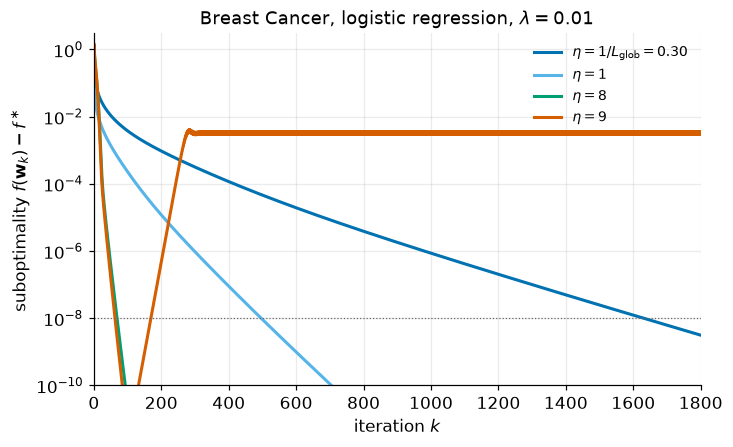

In [13]:
# Figure 7.4 — gradient descent on the logistic loss: the step size decides everything
def figure_7_4():
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    for name, color, ls in [("1/L_glob = 0.30", BLUE, "-"), ("1", SKY, "-"), ("8", GREEN, "-"), ("9", VERMILION, "-")]:
        gaps = gd_runs[name]
        ax.plot(np.arange(len(gaps)), gaps, color=color, lw=2, ls=ls,
                label=(r"$\eta = 1/L_{\mathrm{glob}} = 0.30$" if name.startswith("1/") else rf"$\eta = {name}$"))
    ax.axhline(1e-8, color="0.4", lw=0.8, ls=":")
    ax.set(yscale="log", xlim=(0, 1800), ylim=(1e-10, 3),
           xlabel="iteration $k$", ylabel=r"suboptimality $f(\mathbf{w}_k) - f^\ast$",
           title="Breast Cancer, logistic regression, $\\lambda = 0.01$")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    fig.tight_layout()
    plt.show()


figure_7_4()

How do the theorems of Section 7.3.3 compare with the measurement? For $\eta = 1/L_{\text{glob}}$, Theorem 7.4 guarantees $f(\mathbf{w}_k) - f^\ast \le \lVert\mathbf{w}_0 - \mathbf{w}^\ast\rVert^2/(2\eta k)$, valid because the loss is convex and $L_{\text{glob}}$-smooth. Theorem 7.5 does not apply globally (the unpenalized intercept direction has no uniform lower curvature), but near $\mathbf{w}^\ast$ the function behaves like the quadratic with curvatures $[\mu_{\text{loc}}, L_{\text{loc}}]$, so the suboptimality of the final phase should decay like $(1 - \eta\mu_{\text{loc}})^{2k}$, the square of the rate of the distance.

In [14]:
eta_g = 1 / L_glob
gaps = gd_logistic(eta_g, 3000)
ks = np.arange(1, len(gaps))
dist0 = np.linalg.norm(w_star_b)                         # ||w_0 - w*|| with w_0 = 0
bound_74 = dist0**2 / (2 * eta_g * ks)
print(f"||w_0 - w*||^2 = {dist0**2:.1f}")
print(f"largest ratio measured gap / bound of Theorem 7.4 over k = 1..{len(ks)}: {(gaps[1:] / bound_74).max():.3f}   (must be <= 1)")
rate_loc = 1 - eta_g * mu_loc
late = np.log(gaps[1200] / gaps[1000]) / 200
print(f"measured asymptotic decay per iteration of the gap, k = 1000..1200: {np.exp(late):.5f}")
print(f"local prediction (1 - eta*mu_loc)^2                               : {rate_loc**2:.5f}")

||w_0 - w*||^2 = 5.8
largest ratio measured gap / bound of Theorem 7.4 over k = 1..2999: 0.067   (must be <= 1)
measured asymptotic decay per iteration of the gap, k = 1000..1200: 0.99280
local prediction (1 - eta*mu_loc)^2                               : 0.99412


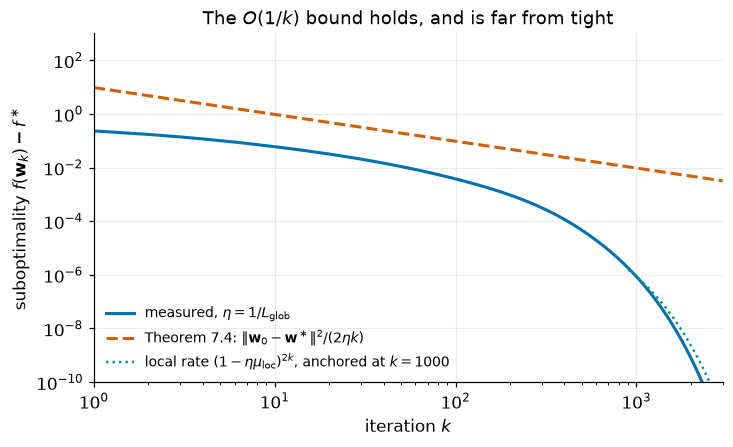

In [15]:
# Figure 7.5 — a guarantee versus a measurement
def figure_7_5():
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ax.plot(ks, gaps[1:], color=BLUE, lw=2, label="measured, $\\eta = 1/L_{\\mathrm{glob}}$")
    ax.plot(ks, bound_74, color=VERMILION, lw=2, ls="--", label=r"Theorem 7.4: $\|\mathbf{w}_0 - \mathbf{w}^\ast\|^2/(2\eta k)$")
    ref = gaps[1000] * rate_loc ** (2 * (ks - 1000))
    ax.plot(ks[900:], ref[900:], color=GREEN, lw=1.6, ls=":", label=r"local rate $(1 - \eta\mu_{\mathrm{loc}})^{2k}$, anchored at $k = 1000$")
    ax.set(yscale="log", xscale="log", xlim=(1, 3000), ylim=(1e-10, 1e3),
           xlabel="iteration $k$", ylabel=r"suboptimality $f(\mathbf{w}_k) - f^\ast$",
           title="The $O(1/k)$ bound holds, and is far from tight")
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_7_5()

The bound holds at every iteration, as it must, and it is loose by many orders of magnitude after a few hundred iterations: the measured curve bends downward into a straight line on the log scale, the signature of linear convergence, at the rate predicted by the *local* curvature. A guarantee tells us what cannot go wrong; it does not predict the speed on a given problem.

### 7.3.5 Choosing the step size automatically: backtracking line search

Both theorems say "take $\eta \le 1/L$", and we have just seen that the $L$ of the theory can be an order of magnitude too large. **Backtracking line search** finds a good step at run time with the descent lemma as its only tool. Fix constants $c \in (0, 1)$ (typically $10^{-4}$) and $\beta \in (0, 1)$ (typically $\tfrac12$); at each iteration start from a trial step $\eta_0$ and multiply it by $\beta$ until the **Armijo condition**
$$
f(\mathbf{w} - \eta\mathbf{g}) \le f(\mathbf{w}) - c\,\eta\,\lVert\mathbf{g}\rVert^2, \qquad \mathbf{g} = \nabla f(\mathbf{w}),
$$
holds (the decrease must be at least a fraction $c$ of what the tangent promises).

:::{admonition} Proposition 7.6 (backtracking terminates)
:class: tip
If $f$ is $L$-smooth and $\mathbf{g} \ne \mathbf{0}$, the Armijo condition holds for every step $\eta \le 2(1 - c)/L$. Consequently backtracking stops after finitely many reductions, and the accepted step satisfies $\eta \ge \min\{\eta_0,\ 2\beta(1 - c)/L\}$.
:::

:::{admonition} Proof
:class: dropdown
By Proposition 7.2, $f(\mathbf{w} - \eta\mathbf{g}) \le f(\mathbf{w}) - \eta(1 - L\eta/2)\lVert\mathbf{g}\rVert^2$, and $1 - L\eta/2 \ge c$ if and only if $\eta \le 2(1 - c)/L$. If $\eta_0$ is already below this threshold it is accepted. Otherwise the loop stops at the first $\eta_0\beta^j$ below the threshold, and the previous trial, $\eta_0\beta^{j-1}$, was above it, so the accepted value exceeds $\beta\cdot 2(1 - c)/L$. $\square$
:::

So backtracking never takes a step smaller than a fixed fraction of $1/L$, and the proofs of Theorems 7.4 and 7.5 go through with that step: the guarantees of the best constant step are kept without knowing $L$. A practical refinement, used below, is to **warm-start** the search by doubling the last accepted step: the step then tracks the local curvature, increasing when the function is flat and shrinking when it is not. Each trial costs one evaluation of the function (but not of the gradient).

For comparison we also run two methods that use curvature information. **L-BFGS** (limited-memory Broyden–Fletcher–Goldfarb–Shanno, available as `scipy.optimize.minimize(method="L-BFGS-B")`) builds an approximation of the *inverse* Hessian from the last few gradient differences, at the cost of a few vectors, and is the default solver of `LogisticRegression`. **Newton's method** (Section 6.4.3) computes the exact Hessian and solves a linear system at every step.

In [16]:
def gd_backtracking(tol=1e-8, eta0=1.0, c=1e-4, beta=0.5, max_iter=3000):
    """GD with Armijo backtracking, warm-started by doubling the last accepted step."""
    w = np.zeros(d_b + 1)
    eta, gaps, n_func, etas = eta0, [], 0, []
    for _ in range(max_iter):
        f, g = logistic_obj(w)
        n_func += 1
        gaps.append(f - f_star_b)
        etas.append(eta)
        if gaps[-1] < tol:
            break
        eta *= 2
        while True:
            f_new = logistic_obj(w - eta * g)[0]
            n_func += 1
            if f_new <= f - c * eta * (g @ g):
                break
            eta *= beta
        w = w - eta * g
    return np.array(gaps), n_func, etas


gaps_bt, n_func_bt, etas_bt = gd_backtracking()
print(f"backtracking: {len(gaps_bt) - 1} gradient steps, {n_func_bt} function evaluations, "
      f"accepted steps from {etas_bt[1]:.2f} to {etas_bt[-2]:.2f}")

# L-BFGS, counting evaluations and recording the gap after every iteration
evals_lbfgs, hist_lbfgs = [0], []
def fun_counted(w):
    evals_lbfgs[0] += 1
    return logistic_obj(w)


def record(w):
    hist_lbfgs.append((logistic_obj(w)[0] - f_star_b, evals_lbfgs[0]))


res = minimize(fun_counted, np.zeros(d_b + 1), jac=True, method="L-BFGS-B", callback=record,
               options={"maxiter": 500, "gtol": 1e-12, "ftol": 1e-16})
hist = np.array(hist_lbfgs)
k_lb = int(np.flatnonzero(hist[:, 0] < 1e-8)[0])
print(f"L-BFGS: gap below 1e-8 after {k_lb + 1} iterations and {int(hist[k_lb, 1])} gradient evaluations")

# Newton
w, newton_gaps = np.zeros(d_b + 1), []
for _ in range(8):
    f, g = logistic_obj(w)
    newton_gaps.append(f - f_star_b)
    w = w - np.linalg.solve(logistic_hessian(w), g)
newton_gaps.append(logistic_obj(w)[0] - f_star_b)
print("Newton, gap after k steps (k = 0..8):", " ".join(f"{v:.1e}" for v in newton_gaps))

backtracking: 57 gradient steps, 169 function evaluations, accepted steps from 2.00 to 8.00
L-BFGS: gap below 1e-8 after 19 iterations and 21 gradient evaluations
Newton, gap after k steps (k = 0..8): 5.9e-01 1.5e-01 6.0e-02 1.7e-02 2.1e-03 5.0e-05 3.6e-08 2.2e-14 0.0e+00


With the warm start, backtracking finds on its own steps that grow to $8$, close to the best constant step ($8.7$, the edge of the stable range), and reaches the target in 57 steps (and 169 function evaluations, of which 111 are the extra trials: backtracking spends about three function evaluations per step to save more than a thousand steps). L-BFGS is faster still, 19 iterations (21 evaluations of the function and the gradient), because it also corrects the *direction*. Newton needs 7 steps and then converges quadratically: from $3.6 \cdot 10^{-8}$ to $2 \cdot 10^{-14}$ in a single step. The price is the cost of an iteration: a gradient costs of the order of $n\,p$ operations, and a Newton step needs the Hessian ($n\,p^2$) and a solve ($p^3$), about $p = 31$ times more here, and a great deal more for the millions of parameters of a neural network, where the Hessian cannot even be stored. Section 7.10 collects these comparisons.

## 7.4 Conditioning and preprocessing

Theorem 7.3 says that the number of iterations is proportional to $\kappa$, and Section 7.2.2 found that the raw Diabetes problem has $\kappa = 7 \cdot 10^4$ against $418$ after standardization. The next result explains *why* rescaling the variables is the same as changing the optimization method.

:::{admonition} Proposition 7.7 (rescaling is preconditioning)
:class: tip
Let $f$ be differentiable, $\mathbf{D}$ an invertible matrix, and $g(\mathbf{v}) = f(\mathbf{D}\mathbf{v})$. Gradient descent on $g$, $\mathbf{v}_{k+1} = \mathbf{v}_k - \eta\nabla g(\mathbf{v}_k)$, produces, in the original variables $\mathbf{w}_k = \mathbf{D}\mathbf{v}_k$, the iteration
$$
\mathbf{w}_{k+1} = \mathbf{w}_k - \eta\,\mathbf{M}\,\nabla f(\mathbf{w}_k), \qquad \mathbf{M} = \mathbf{D}\mathbf{D}^\top \succ 0,
$$
called **preconditioned gradient descent**. If $f$ is quadratic with Hessian $\mathbf{H}$, the Hessian of $g$ is $\mathbf{D}^\top\mathbf{H}\mathbf{D}$, whose eigenvalues are those of $\mathbf{M}\mathbf{H}$, and the speed of the iteration is governed by $\kappa(\mathbf{M}\mathbf{H}) = \kappa(\mathbf{D}^\top\mathbf{H}\mathbf{D})$.
:::

:::{admonition} Proof
:class: dropdown
By the chain rule $\nabla g(\mathbf{v}) = \mathbf{D}^\top\nabla f(\mathbf{D}\mathbf{v})$, so $\mathbf{w}_{k+1} = \mathbf{D}\mathbf{v}_{k+1} = \mathbf{w}_k - \eta\mathbf{D}\mathbf{D}^\top\nabla f(\mathbf{w}_k)$. For a quadratic, $\nabla^2 g = \mathbf{D}^\top\mathbf{H}\mathbf{D}$. The matrices $\mathbf{D}^\top\mathbf{H}\mathbf{D}$ and $\mathbf{D}\mathbf{D}^\top\mathbf{H}$ are similar (conjugate by $\mathbf{D}$), hence they have the same eigenvalues. $\square$
:::

Two examples show the range of the idea. **Standardization is a diagonal preconditioner.** Dividing column $j$ of the (centered) design matrix by its standard deviation $s_j$ is a change of variables $\mathbf{w} = \mathbf{D}\mathbf{v}$ with $\mathbf{D} = \mathrm{diag}(1/s_j)$, and since the diagonal of the Hessian $\frac1n\mathbf{X}^\top\mathbf{X}$ is exactly $s_j^2$, the preconditioner $\mathbf{M} = \mathrm{diag}(1/s_j^2)$ is the inverse of the diagonal of $\mathbf{H}$ (the *Jacobi* preconditioner). **Newton's method is the perfect preconditioner.** Take $\mathbf{M} = \mathbf{H}^{-1}$: then $\mathbf{M}\mathbf{H} = \mathbf{I}$, $\kappa = 1$, and with $\eta = 1$ a quadratic is solved in one step. All the second-order methods of Section 7.3.5 are attempts to approximate $\mathbf{H}^{-1}$ at a price lower than the Hessian itself.

The next cell checks Proposition 7.7 on the Diabetes data, running the iteration in the raw units with the Jacobi preconditioner and in the standardized units, and then uses the exact formula of Theorem 7.3 to count the iterations that gradient descent needs in the four situations of Section 7.2.2 (with $\eta = 1/L$ for each, starting from $\mathbf{w} = \mathbf{0}$) to reduce the distance to the minimizer by a factor $10^{3}$. Using the formula is legitimate because the objective is exactly quadratic, and it lets us count iterations in the hundreds of thousands without running them; the cell first checks the formula against a direct run of $3000$ iterations.

In [17]:
# Proposition 7.7: gradient descent on standardized variables = preconditioned gradient descent on raw variables
Xc_raw = Xd_tr - Xd_tr.mean(axis=0)
s_raw = Xd_tr.std(axis=0)                                    # the scale used by StandardScaler
H_raw, b_raw = Xc_raw.T @ Xc_raw / n_d, Xc_raw.T @ yd_c / n_d
M_jacobi = np.diag(1 / s_raw**2)
print("diagonal of the raw Hessian equals the variances of the columns:", np.allclose(np.diag(H_raw), s_raw**2))

eta_std = 1 / L_d                                            # L_d: largest eigenvalue of the standardized Hessian
v = np.zeros(10)
w_pre = np.zeros(10)
for _ in range(200):
    v = v - eta_std * (H_d @ v - b_d)                         # standardized variables
    w_pre = w_pre - eta_std * M_jacobi @ (H_raw @ w_pre - b_raw)   # raw variables, preconditioned
print(f"largest difference between D v_200 and the preconditioned iterate: {np.abs(v / s_raw - w_pre).max():.1e}")


def quad_curves(H, b, ks, eta):
    """Exact distance ||w_k - w*|| / ||w_0 - w*|| and suboptimality of GD from w = 0 on 1/2 w'Hw - b'w, for the
    iteration counts ks, from the eigen-decomposition of Theorem 7.3."""
    ev, V = np.linalg.eigh(H)
    c = V.T @ np.linalg.solve(H, b)                           # coordinates of w_0 - w* = -w*, up to sign
    shrink = (1 - eta * ev[None, :]) ** (2 * ks[:, None])
    return np.sqrt((shrink * c[None, :] ** 2).sum(axis=1) / (c**2).sum()), 0.5 * (shrink * ev[None, :] * c[None, :] ** 2).sum(axis=1)


# check the formulas against a direct run of 3000 iterations (standardized, lambda = 0)
ks_chk = np.arange(0, 3001)
w_run, dist_run, gap_run = np.zeros(10), [], []
for _ in ks_chk:
    e = w_run - w_star_d
    dist_run.append(np.linalg.norm(e) / np.linalg.norm(w_star_d))
    gap_run.append(0.5 * e @ H_d @ e)
    w_run = w_run - (1 / L_d) * (H_d @ w_run - b_d)
dist_formula, gap_formula = quad_curves(H_d, b_d, ks_chk, 1 / L_d)
print(f"largest relative difference, distance: {np.max(np.abs(np.array(dist_run) - dist_formula) / dist_formula):.1e}, "
      f"suboptimality: {np.max(np.abs(np.array(gap_run) - gap_formula) / gap_formula):.1e}")

diagonal of the raw Hessian equals the variances of the columns: True
largest difference between D v_200 and the preconditioned iterate: 1.6e-13
largest relative difference, distance: 1.9e-12, suboptimality: 3.9e-12


In [18]:
setups = [("raw units, lambda = 0", H_raw, b_raw, 0.0),
          ("standardized, lambda = 0", H_d, b_d, 0.0),
          ("standardized, lambda = 0.1", H_d + 0.1 * np.eye(10), b_d, 0.1),
          ("standardized, lambda = 1", H_d + 1.0 * np.eye(10), b_d, 1.0)]
ks_log = np.unique(np.logspace(0, 7.5, 4000).astype(np.int64))
rows, gap_curves = [], {}
for name, H, b, lam in setups:
    ev = np.linalg.eigvalsh(H)
    eta = 1 / ev[-1]
    dist, _ = quad_curves(H, b, ks_log, eta)
    gap_curves[name] = (ks_log, dist)
    k_hit = ks_log[np.flatnonzero(dist < 1e-3)[0]]
    rows.append({"problem": name, "kappa": ev[-1] / ev[0], "iterations": k_hit, "iterations / kappa": k_hit / (ev[-1] / ev[0])})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

                   problem     kappa  iterations  iterations / kappa
     raw units, lambda = 0 7.434e+04      509391               6.853
  standardized, lambda = 0     417.8        2799               6.699
standardized, lambda = 0.1     36.74         176                4.79
  standardized, lambda = 1     4.873          15               3.078


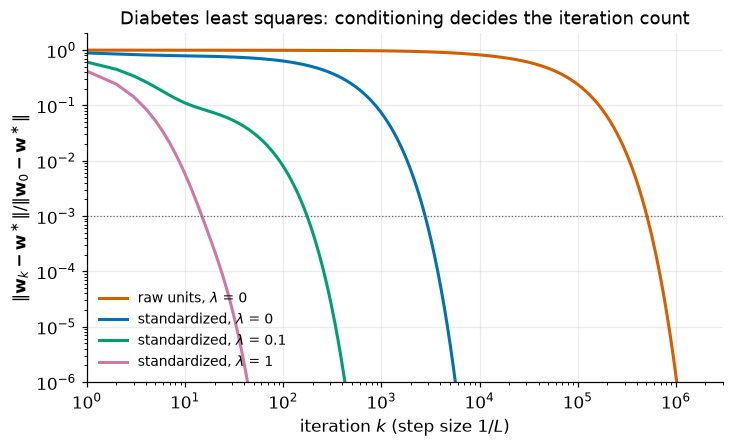

In [19]:
# Figure 7.6 — preconditioning by standardization, and the effect of the ridge penalty on the speed of GD
def figure_7_6():
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    for (name, (kk, gg)), color in zip(gap_curves.items(), [VERMILION, BLUE, GREEN, PURPLE]):
        label = name.replace("lambda", r"$\lambda$")
        ax.plot(kk, gg, color=color, lw=2, label=label)
    ax.axhline(1e-3, color="0.4", lw=0.8, ls=":")
    ax.set(xscale="log", yscale="log", xlim=(1, 3e6), ylim=(1e-6, 2),
           xlabel="iteration $k$ (step size $1/L$)", ylabel=r"$\|\mathbf{w}_k - \mathbf{w}^\ast\| / \|\mathbf{w}_0 - \mathbf{w}^\ast\|$",
           title="Diabetes least squares: conditioning decides the iteration count")
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_7_6()

The raw problem needs $509{,}391$ iterations to bring the iterate within a thousandth of the distance to the minimizer, the standardized problem $2{,}799$, and the standardized problem with $\lambda = 0.1$ and $\lambda = 1$ only $176$ and $15$. For the first two, the ratio of iterations to $\kappa$ is $6.9 = \ln 10^3$, which is the worst case $\kappa\ln(1/\varepsilon)$ of Theorem 7.3 with $\eta = 1/L$ (the starting error has weight along the flattest direction); with the ridge penalty the ratio is smaller because the starting error has little weight there. Standardizing the features made gradient descent about $180$ times faster *without changing the model or its solution*, and each additional ridge penalty makes it faster again, because adding $\lambda$ to every eigenvalue is precisely a reduction of $\kappa$ (Section 7.2.2): the penalty that stabilizes the statistics in Chapter 6 also stabilizes the optimization.

:::{admonition} Pitfall — an optimizer that "stops moving" has not necessarily converged
:class: warning
On the raw Diabetes features the distance to the minimizer is still essentially unchanged after $10^4$ iterations (Figure 7.6): the iteration is crawling along a long, almost flat valley, and a stopping rule based only on the change of the loss is easily fooled by it. Two defenses: standardize the features before using any iterative solver, and monitor the **norm of the gradient** (which is zero at a minimizer of a smooth convex function) in addition to the change of the loss. Scikit-learn's iterative solvers use tolerances of this kind and raise a `ConvergenceWarning` when `max_iter` is exhausted: that warning means "this is not the minimizer", and it deserves attention.
:::

## 7.5 Momentum and acceleration

Theorem 7.3 and Figure 7.6 deliver a sobering message: on an ill-conditioned problem the best constant step cannot beat the rate $(\kappa - 1)/(\kappa + 1)$. The iteration is slow because the gradient points mostly across the narrow valley (the zigzag of Figure 7.2) and only a little along it. **Momentum** uses the memory of the previous steps: the components of the gradient that keep changing sign cancel, those that keep the same sign add up.

The **heavy-ball method** (Polyak, 1964) adds to the gradient step a fraction $\beta \in [0, 1)$ of the previous displacement,

$$
\mathbf{w}_{k+1} = \mathbf{w}_k - \eta\nabla f(\mathbf{w}_k) + \beta(\mathbf{w}_k - \mathbf{w}_{k-1}),
$$

which is the discretization of a ball rolling in the landscape $f$ with friction (the velocity is $\mathbf{v}_{k+1} = \beta\mathbf{v}_k - \eta\nabla f(\mathbf{w}_k)$ and the position $\mathbf{w}_{k+1} = \mathbf{w}_k + \mathbf{v}_{k+1}$). **Nesterov's accelerated gradient** (1983) evaluates the gradient at the point reached by the momentum step instead of at the current point:

$$
\mathbf{y}_k = \mathbf{w}_k + \beta_k(\mathbf{w}_k - \mathbf{w}_{k-1}),
\qquad
\mathbf{w}_{k+1} = \mathbf{y}_k - \eta\nabla f(\mathbf{y}_k).
$$

Both need one gradient per iteration and one extra vector of memory. For quadratics the gain is exactly the replacement of $\kappa$ by $\sqrt\kappa$.

:::{admonition} Theorem 7.8 (heavy ball on a quadratic)
:class: tip
Let $f(\mathbf{w}) = \frac12\mathbf{w}^\top\mathbf{H}\mathbf{w} - \mathbf{b}^\top\mathbf{w}$ with the eigenvalues of $\mathbf{H}$ in $[\mu, L]$, and let
$$
\eta = \frac{4}{(\sqrt L + \sqrt\mu)^2},
\qquad
\beta = \Big(\frac{\sqrt\kappa - 1}{\sqrt\kappa + 1}\Big)^2 .
$$
Then every eigen-component of the error $\mathbf{w}_k - \mathbf{w}^\ast$ is bounded by a constant times $(k + 1)\rho^k$, with
$$
\rho = \sqrt\beta = \frac{\sqrt\kappa - 1}{\sqrt\kappa + 1} .
$$
To reduce the error by a factor $\varepsilon$ the method needs about $\frac{\sqrt\kappa}{2}\ln(1/\varepsilon)$ iterations (up to the factor $k + 1$, which is logarithmic in the count), against $\frac\kappa2\ln(1/\varepsilon)$ for the best gradient descent.
:::

:::{admonition} Proof
:class: dropdown
In the eigenbasis of $\mathbf{H}$ the iteration decouples. For the eigenvalue $\lambda$, the error component $e_k$ satisfies $e_{k+1} = (1 + \beta - \eta\lambda)e_k - \beta e_{k-1}$, a linear recursion of order two whose behavior is governed by the roots of $z^2 - (1 + \beta - \eta\lambda)z + \beta = 0$. Their product is $\beta$. If the discriminant is negative, $(1 + \beta - \eta\lambda)^2 < 4\beta$, the roots are complex conjugates and both have modulus $\sqrt\beta$; if it is zero there is a double root of modulus $\sqrt\beta$ and $e_k$ grows like $(k + 1)\sqrt\beta^{\,k}$. The condition $\lvert 1 + \beta - \eta\lambda\rvert \le 2\sqrt\beta$ is equivalent to $(1 - \sqrt\beta)^2 \le \eta\lambda \le (1 + \sqrt\beta)^2$. With the stated $\beta$ one has $\sqrt\beta = (\sqrt\kappa - 1)/(\sqrt\kappa + 1)$, hence $(1 - \sqrt\beta)^2 = 4/(\sqrt\kappa + 1)^2 = \eta\mu$ and $(1 + \sqrt\beta)^2 = 4\kappa/(\sqrt\kappa + 1)^2 = \eta L$. Every $\lambda \in [\mu, L]$ therefore lies in the range, and all the components contract at the rate $\sqrt\beta$ (up to the polynomial factor). Finally $\ln(1/\rho) = 2\,\mathrm{artanh}(1/\sqrt\kappa) \ge 2/\sqrt\kappa$. $\square$
:::

Nesterov's method is more remarkable because its guarantee holds for every smooth convex function, not only for quadratics, and it cannot be improved by any method that uses only gradients.

:::{admonition} Theorem 7.9 (Nesterov, 1983; stated without proof)
:class: tip
Let $f$ be convex and $L$-smooth. Accelerated gradient with $\eta = 1/L$ and $\beta_k = k/(k + 3)$ satisfies
$$
f(\mathbf{w}_k) - f(\mathbf{w}^\ast) \le \frac{2L\lVert\mathbf{w}_0 - \mathbf{w}^\ast\rVert^2}{(k + 1)^2} ,
$$
an $O(1/k^2)$ rate against the $O(1/k)$ of Theorem 7.4. If $f$ is also $\mu$-strongly convex, the choice $\beta = (\sqrt\kappa - 1)/(\sqrt\kappa + 1)$ with $\eta = 1/L$ gives a suboptimality of order $(1 - 1/\sqrt\kappa)^k$, that is $O(\sqrt\kappa\log(1/\varepsilon))$ iterations. These rates are optimal for first-order methods in the worst case (Nemirovski and Yudin, 1983).
:::

(The proof, by "estimate sequences", is in Nesterov's book *Lectures on Convex Optimization*, 2018, and a short proof by a Lyapunov argument is in Bubeck's monograph; both are listed under Further reading.) A caution: unlike gradient descent with $\eta \le 1/L$, momentum methods are **not descent methods**: the objective can go up for a few iterations before it goes down faster.

We check the $\sqrt\kappa$ on the two problems of this chapter. First, the Diabetes least-squares problem ($\kappa = 418$, $\sqrt\kappa = 20.4$), with the parameters of Theorems 7.3 and 7.8 and the strongly convex version of Nesterov's method.

In [20]:
def momentum_run(grad, record, w0, eta, beta_fn, iters, kind):
    """Heavy ball ('hb'), Nesterov ('nag') or plain gradient descent (beta = 0); returns record(w_k), k = 0..iters-1."""
    w, w_prev, out = w0.copy(), w0.copy(), np.empty(iters)
    for k in range(iters):
        out[k] = record(w)
        if kind == "hb":
            w_new = w - eta * grad(w) + beta_fn(k) * (w - w_prev)
        else:
            y = w + beta_fn(k) * (w - w_prev)
            w_new = y - eta * grad(y)
        w_prev, w = w, w_new
    return out


grad_d = lambda w: H_d @ w - b_d
dist_d = lambda w: np.linalg.norm(w - w_star_d) / np.linalg.norm(w_star_d)
sk = np.sqrt(kappa_d)
eta_hb = 4 / (np.sqrt(L_d) + np.sqrt(mu_d)) ** 2
beta_hb = ((sk - 1) / (sk + 1)) ** 2
beta_nag = (sk - 1) / (sk + 1)
w0_d = np.zeros(10)
methods_d = {
    "gradient descent, eta = 1/L":           (1 / L_d, lambda k: 0.0, "hb"),
    "gradient descent, eta = 2/(L+mu)":      (2 / (L_d + mu_d), lambda k: 0.0, "hb"),
    "heavy ball (Theorem 7.8)":              (eta_hb, lambda k: beta_hb, "hb"),
    "Nesterov, strongly convex version":      (1 / L_d, lambda k: beta_nag, "nag"),
}
curves_d, rows = {}, []
for name, (eta, bfn, kind) in methods_d.items():
    curves_d[name] = momentum_run(grad_d, dist_d, w0_d, eta, bfn, 20_000, kind)
    hit = np.flatnonzero(curves_d[name] < 1e-6)
    rows.append({"method": name, "iterations to reduce the distance by 1e-6": int(hit[0]) if len(hit) else "not reached"})
print(pd.DataFrame(rows).to_string(index=False))
rho_hb = np.sqrt(beta_hb)
print(f"heavy ball: rho = {rho_hb:.4f}, ln(1e6)/ln(1/rho) = {np.log(1e6) / np.log(1 / rho_hb):.0f}; "
      f"best gradient descent: (kappa/2) ln(1e6) = {kappa_d / 2 * np.log(1e6):.0f}")

                           method  iterations to reduce the distance by 1e-6
      gradient descent, eta = 1/L                                       5677
 gradient descent, eta = 2/(L+mu)                                       2856
         heavy ball (Theorem 7.8)                                        190
Nesterov, strongly convex version                                        328
heavy ball: rho = 0.9067, ln(1e6)/ln(1/rho) = 141; best gradient descent: (kappa/2) ln(1e6) = 2886


Second, the logistic regression of Section 7.3.4, at the step $\eta = 1/L_{\text{glob}}$ that the theory recommends, with $\mu = \lambda$ for the strongly convex version (the curvature that the penalty guarantees) and a few values of the heavy-ball momentum. For a general (non-quadratic) function there is no optimal $\beta$ in closed form, and the heavy ball needs tuning.

In [21]:
grad_b = lambda w: logistic_obj(w)[1]
gap_b = lambda w: logistic_obj(w)[0] - f_star_b
eta_b = 1 / L_glob
q = np.sqrt(lam_b * eta_b)
w0_b = np.zeros(d_b + 1)
methods_b = {
    "gradient descent":                    (lambda k: 0.0, "hb"),
    "Nesterov, strongly convex version":   (lambda k: (1 - q) / (1 + q), "nag"),
    "Nesterov, beta_k = k/(k+3)":          (lambda k: k / (k + 3), "nag"),
    "heavy ball, beta = 0.8":              (lambda k: 0.8, "hb"),
    "heavy ball, beta = 0.9":              (lambda k: 0.9, "hb"),
    "heavy ball, beta = 0.95":             (lambda k: 0.95, "hb"),
}
curves_b, rows = {}, []
for name, (bfn, kind) in methods_b.items():
    curves_b[name] = momentum_run(grad_b, gap_b, w0_b, eta_b, bfn, 3000, kind)
    rows.append({"method (eta = 1/L_glob = 0.30)": name, "iterations to gap < 1e-8": iterations_to(curves_b[name]),
                 "largest increase of the gap in one step": np.max(np.diff(curves_b[name]))})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2g}"))

   method (eta = 1/L_glob = 0.30)  iterations to gap < 1e-8  largest increase of the gap in one step
                 gradient descent                      1631                                 -6.9e-15
Nesterov, strongly convex version                       146                                   0.0025
       Nesterov, beta_k = k/(k+3)                       564                                  5.2e-06
           heavy ball, beta = 0.8                       310                                  6.9e-17
           heavy ball, beta = 0.9                       172                                   0.0054
          heavy ball, beta = 0.95                       338                                    0.014


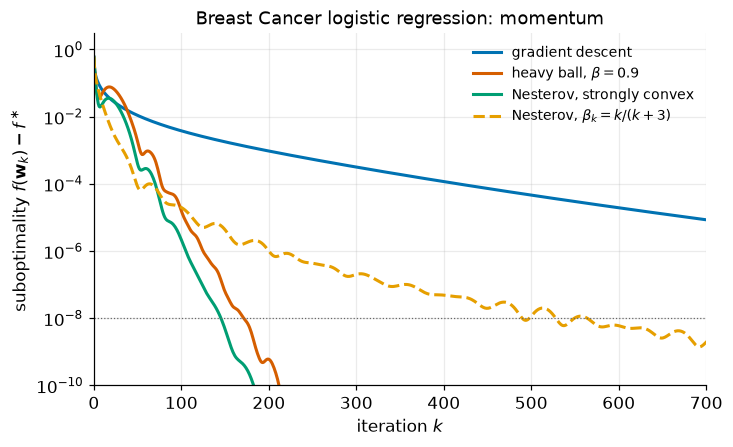

In [22]:
# Figure 7.7 — momentum on the logistic regression (eta = 1/L_glob for all)
def figure_7_7():
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    for name, color, ls, label in [("gradient descent", BLUE, "-", "gradient descent"),
                                   ("heavy ball, beta = 0.9", VERMILION, "-", r"heavy ball, $\beta = 0.9$"),
                                   ("Nesterov, strongly convex version", GREEN, "-", "Nesterov, strongly convex"),
                                   ("Nesterov, beta_k = k/(k+3)", ORANGE, "--", r"Nesterov, $\beta_k = k/(k+3)$")]:
        ax.plot(np.maximum(curves_b[name], 1e-12), color=color, lw=2, ls=ls, label=label)
    ax.axhline(1e-8, color="0.4", lw=0.8, ls=":")
    ax.set(yscale="log", xlim=(0, 700), ylim=(1e-10, 3),
           xlabel="iteration $k$", ylabel=r"suboptimality $f(\mathbf{w}_k) - f^\ast$",
           title="Breast Cancer logistic regression: momentum")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    fig.tight_layout()
    plt.show()


figure_7_7()

## 7.6 Stochastic gradient descent

### 7.6.1 The stochastic gradient

The objective of supervised learning is an average over the training set, $f(\mathbf{w}) = \frac1n\sum_i\ell_i(\mathbf{w}) + \frac\lambda2\lVert\mathbf{w}\rVert^2$, and its gradient is the average of $n$ per-example gradients plus the penalty gradient. Computing it costs a pass over all the data; when $n$ is in the millions, or the data do not fit in memory, this is too much to pay for a single small step. The key observation of **stochastic gradient descent** (SGD, Robbins and Monro, 1951) is that an average can be *estimated* from a few terms. At each iteration draw a random **mini-batch** $\mathcal{B}_k$ of $B$ indices and move along

$$
\mathbf{g}_k = \frac1B\sum_{i \in \mathcal{B}_k}\nabla\ell_i(\mathbf{w}_k) + \lambda\mathbf{w}_k,
\qquad
\mathbf{w}_{k+1} = \mathbf{w}_k - \eta_k\,\mathbf{g}_k .
$$

The two extreme cases have names: $B = 1$ is "pure" SGD and $B = n$ is full-batch gradient descent. The next result says what the estimate is worth.

:::{admonition} Proposition 7.10 (the mini-batch gradient)
:class: tip
Let the $B$ indices be drawn independently and uniformly from $\{1, \dots, n\}$ (with replacement) and let $\mathbf{u}_i = \nabla\ell_i(\mathbf{w})$, with mean $\bar{\mathbf{u}} = \nabla f(\mathbf{w}) - \lambda\mathbf{w}$ and per-example variance $\sigma^2(\mathbf{w}) = \frac1n\sum_i\lVert\mathbf{u}_i - \bar{\mathbf{u}}\rVert^2$. Then
$$
\mathbb{E}[\mathbf{g}] = \nabla f(\mathbf{w}),
\qquad
\mathbb{E}\,\lVert\mathbf{g} - \nabla f(\mathbf{w})\rVert^2 = \frac{\sigma^2(\mathbf{w})}{B}.
$$
If the indices are drawn without replacement the variance is multiplied by $(n - B)/(n - 1) \le 1$, and it is zero for $B = n$.
:::

:::{admonition} Proof
:class: dropdown
The batch gradient is the mean of $B$ independent copies of a random vector that equals $\mathbf{u}_i$ with probability $1/n$; its mean is $\bar{\mathbf{u}}$ (the penalty term is deterministic) and the variance of the mean of independent vectors is the variance of one divided by $B$. Without replacement the draws are negatively correlated, and the classical finite-population correction applies. $\square$
:::

Two consequences. The mini-batch gradient is **unbiased**, so on average SGD moves like GD; and **its noise decreases only like $1/B$**, that is the standard deviation like $1/\sqrt B$: to halve the noise one needs four times as many examples per step. Moreover the variance $\sigma^2(\mathbf{w})$ does **not** vanish at the minimizer: at $\mathbf{w}^\ast$ the *average* of the per-example gradients is (minus the penalty gradient, hence) small, but each example still pulls in its own direction. This is the origin of the noise floor of Section 7.6.2.

### Worked example 7.3 — the mini-batch gradient of the three-point line fit

Return to the three points $(0, 1)$, $(1, 3)$, $(2, 4)$ of Worked example 1.2, the model $y = b + wx$, the loss $\ell_i = \frac12(b + wx_i - y_i)^2$ and the starting point $(b, w) = (0, 0)$. The per-example gradients are (residual) $\times$ (features) $= -y_i(1, x_i)$:
$$
\mathbf{u}_1 = (-1, 0), \qquad \mathbf{u}_2 = (-3, -3), \qquad \mathbf{u}_3 = (-4, -8),
$$
and the full gradient is their mean, $\bar{\mathbf{u}} = (-\tfrac83, -\tfrac{11}3)$. The variance is $\sigma^2 = \frac13\big(\frac{146}9 + \frac59 + \frac{185}9\big) = \frac{112}9 = 12.44$. With mini-batches of $B = 2$ drawn without replacement there are three equally likely batches, with gradients $(-2, -1.5)$, $(-2.5, -4)$ and $(-3.5, -5.5)$: their mean is $\bar{\mathbf{u}}$ (unbiased), and their mean squared distance to $\bar{\mathbf{u}}$ is $\frac13(5.14 + 0.14 + 4.06) = 3.11$, which is exactly $\frac{\sigma^2}{B}\cdot\frac{n - B}{n - 1} = \frac{12.44}{2}\cdot\frac12 = 3.11$.

In [23]:
X3 = np.array([[1.0, 0.0], [1.0, 1.0], [1.0, 2.0]])
y3 = np.array([1.0, 3.0, 4.0])
U = X3 * (X3 @ np.zeros(2) - y3)[:, None]                  # per-example gradients at (b, w) = (0, 0)
u_bar = U.mean(axis=0)
sigma2 = np.mean(np.sum((U - u_bar) ** 2, axis=1))
batches = [(0, 1), (0, 2), (1, 2)]
G = np.array([U[list(bt)].mean(axis=0) for bt in batches])
print("per-example gradients:", U.tolist())
print("full gradient:", u_bar, " sigma^2 =", round(sigma2, 3))
print("mini-batch gradients:", G.tolist())
print("mean of the mini-batch gradients:", G.mean(axis=0))
print(f"mean squared deviation {np.mean(np.sum((G - u_bar) ** 2, axis=1)):.3f} vs sigma^2/B*(n-B)/(n-1) = {sigma2 / 2 * 1 / 2:.3f}")

per-example gradients: [[-1.0, -0.0], [-3.0, -3.0], [-4.0, -8.0]]
full gradient: [-2.66666667 -3.66666667]  sigma^2 = 12.444
mini-batch gradients: [[-2.0, -1.5], [-2.5, -4.0], [-3.5, -5.5]]
mean of the mini-batch gradients: [-2.66666667 -3.66666667]
mean squared deviation 3.111 vs sigma^2/B*(n-B)/(n-1) = 3.111


We now check Proposition 7.10 on the Breast Cancer logistic regression, at the starting point $\mathbf{w} = \mathbf{0}$ and at the minimizer $\mathbf{w}^\ast$, for $B = 1, 16, 128$. For each case we draw $4{,}000$ mini-batches, compare their mean with the full data gradient and their mean squared deviation with $\sigma^2/B$ (and, for $B = 128$, with the correction for sampling without replacement).

In [24]:
def example_gradients(w):
    """n x p matrix whose rows are the gradients of the individual logistic losses (without the penalty)."""
    return Zb1 * (expit(Zb1 @ w) - yb_tr)[:, None]


rng = np.random.default_rng(SEED)
rows = []
for point, w in [("w = 0", np.zeros(d_b + 1)), ("w = w*", w_star_b)]:
    Gx = example_gradients(w)
    g_data = Gx.mean(axis=0)
    s2 = np.mean(np.sum((Gx - g_data) ** 2, axis=1))
    for B, replace in [(1, True), (16, True), (128, True), (128, False)]:
        draws = np.array([Gx[rng.choice(n_b, B, replace=replace)].mean(axis=0) for _ in range(4000)])
        corr = 1.0 if replace else (n_b - B) / (n_b - 1)
        rows.append({"point": point, "B": B, "replacement": "yes" if replace else "no",
                     "||mean of draws - full gradient||": np.linalg.norm(draws.mean(axis=0) - g_data),
                     "measured E||g_B - grad||^2": np.mean(np.sum((draws - g_data) ** 2, axis=1)),
                     "sigma^2 / B (corrected)": s2 / B * corr})
    print(f"{point}: ||full data gradient|| = {np.linalg.norm(g_data):.4f}, per-example variance sigma^2 = {s2:.4f}")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

w = 0: ||full data gradient|| = 1.3913, per-example variance sigma^2 = 5.8143


w = w*: ||full data gradient|| = 0.0237, per-example variance sigma^2 = 0.2695
 point   B replacement  ||mean of draws - full gradient||  measured E||g_B - grad||^2  sigma^2 / B (corrected)
 w = 0   1         yes                            0.04093                       5.854                    5.814
 w = 0  16         yes                            0.01012                      0.3613                   0.3634
 w = 0 128         yes                           0.003419                     0.04605                  0.04542
 w = 0 128          no                           0.002288                     0.03163                  0.03185
w = w*   1         yes                            0.01023                      0.2647                   0.2695
w = w*  16         yes                           0.001599                     0.01714                  0.01685
w = w* 128         yes                          0.0006568                    0.002064                 0.002106
w = w* 128          no           

At the minimizer the full gradient of the data term is small (it only balances the penalty), but the per-example variance is not: the noise of SGD does not die out as we approach the solution.

### 7.6.2 How fast does SGD converge?

To measure the effect of the noise we need an assumption on it. Assume that $f$ is $L$-smooth and $\mu$-strongly convex, that the stochastic gradient is unbiased, $\mathbb{E}[\mathbf{g}_k \mid \mathbf{w}_k] = \nabla f(\mathbf{w}_k)$, and that its variance is bounded, $\mathbb{E}[\lVert\mathbf{g}_k - \nabla f(\mathbf{w}_k)\rVert^2 \mid \mathbf{w}_k] \le \sigma^2$ (for mini-batches, $\sigma^2$ stands for the per-example variance divided by $B$, by Proposition 7.10). The proofs use one more fact about strongly convex functions.

**Lemma (Polyak–Łojasiewicz inequality).** If $f$ is $\mu$-strongly convex, then $\lVert\nabla f(\mathbf{w})\rVert^2 \ge 2\mu\,(f(\mathbf{w}) - f^\ast)$ for all $\mathbf{w}$. *Proof.* Minimize both sides of the strong-convexity inequality $f(\mathbf{y}) \ge f(\mathbf{w}) + \nabla f(\mathbf{w})^\top(\mathbf{y} - \mathbf{w}) + \frac\mu2\lVert\mathbf{y} - \mathbf{w}\rVert^2$ over $\mathbf{y}$: the right side is minimized at $\mathbf{y} = \mathbf{w} - \nabla f(\mathbf{w})/\mu$, with value $f(\mathbf{w}) - \lVert\nabla f(\mathbf{w})\rVert^2/(2\mu)$, and the left side at $\mathbf{y} = \mathbf{w}^\ast$ has value $f^\ast$. $\square$

:::{admonition} Theorem 7.11 (SGD with a constant step size)
:class: tip
Under these assumptions, SGD with a constant step $0 < \eta \le 1/L$ satisfies
$$
\mathbb{E}\big[f(\mathbf{w}_k)\big] - f^\ast \le (1 - \eta\mu)^k\,\big(f(\mathbf{w}_0) - f^\ast\big) + \frac{L\eta\sigma^2}{2\mu}.
$$
:::

:::{admonition} Proof
:class: dropdown
Apply the descent lemma (Proposition 7.2) to the random step $-\eta\mathbf{g}_k$, and take the expectation conditionally on $\mathbf{w}_k$. Since $\mathbb{E}[\mathbf{g}_k] = \nabla f(\mathbf{w}_k)$ and $\mathbb{E}\lVert\mathbf{g}_k\rVert^2 = \lVert\nabla f(\mathbf{w}_k)\rVert^2 + \mathbb{E}\lVert\mathbf{g}_k - \nabla f(\mathbf{w}_k)\rVert^2 \le \lVert\nabla f(\mathbf{w}_k)\rVert^2 + \sigma^2$,
$$
\mathbb{E}[f(\mathbf{w}_{k+1}) \mid \mathbf{w}_k] \le f(\mathbf{w}_k) - \eta\Big(1 - \frac{L\eta}2\Big)\lVert\nabla f(\mathbf{w}_k)\rVert^2 + \frac{L\eta^2\sigma^2}2
\le f(\mathbf{w}_k) - \frac\eta2\lVert\nabla f(\mathbf{w}_k)\rVert^2 + \frac{L\eta^2\sigma^2}2,
$$
using $\eta \le 1/L$. By the Polyak–Łojasiewicz inequality $\lVert\nabla f\rVert^2 \ge 2\mu(f - f^\ast)$, so with $\delta_k = \mathbb{E}[f(\mathbf{w}_k)] - f^\ast$ we get $\delta_{k+1} \le (1 - \eta\mu)\delta_k + \frac{L\eta^2\sigma^2}2$. Unrolling the recursion and bounding the geometric sum $\sum_j(1 - \eta\mu)^j \le 1/(\eta\mu)$,
$$
\delta_k \le (1 - \eta\mu)^k\delta_0 + \frac{L\eta^2\sigma^2}2\cdot\frac1{\eta\mu} . \qquad\square
$$
:::

The bound has two terms. The first forgets the starting point at the *same linear rate as gradient descent*. The second is an **error floor proportional to $\eta\sigma^2$**: with a constant step SGD does not converge to the minimum, it hovers around it at a distance fixed by the step size and by the noise. Reducing the step lowers the floor in proportion, and lengthens the time $1/(\eta\mu)$ needed to reach it. Since $\sigma^2$ is the per-example variance divided by $B$, the floor is proportional to $\eta/B$: when the batch is multiplied by $m$, the same floor is obtained with a step $m$ times larger (the "linear scaling rule", valid while $\eta$ stays below $1/L$).

The way out of the trade-off is to shrink the step as the iteration proceeds.

:::{admonition} Theorem 7.12 (SGD with a decreasing step size)
:class: tip
Under the same assumptions, let $\eta_k = \beta/(\gamma + k)$ with $\beta > 1/\mu$ and $\gamma > 0$ such that $\eta_0 = \beta/\gamma \le 1/L$. Then for every $k \ge 0$
$$
\mathbb{E}\big[f(\mathbf{w}_k)\big] - f^\ast \le \frac{\nu}{\gamma + k},
\qquad
\nu = \max\Big\{\frac{\beta^2L\sigma^2}{2(\beta\mu - 1)},\ \gamma\,(f(\mathbf{w}_0) - f^\ast)\Big\}.
$$
:::

:::{admonition} Proof
:class: dropdown
The one-step inequality of the previous proof holds with $\eta_k$ in place of $\eta$: $\delta_{k+1} \le (1 - \eta_k\mu)\delta_k + L\eta_k^2\sigma^2/2$, and $1 - \eta_k\mu \ge 0$ because $\eta_k \le \eta_0 \le 1/L \le 1/\mu$. We prove $\delta_k \le \nu/(\gamma + k)$ by induction. For $k = 0$ it holds because $\nu \ge \gamma\delta_0$. If it holds for $k$, then
$$
\delta_{k+1} \le \Big(1 - \frac{\beta\mu}{\gamma + k}\Big)\frac\nu{\gamma + k} + \frac{L\beta^2\sigma^2}{2(\gamma + k)^2}
= \frac{(\gamma + k - 1)\,\nu}{(\gamma + k)^2} - \frac{(\beta\mu - 1)\,\nu - L\beta^2\sigma^2/2}{(\gamma + k)^2} .
$$
The last fraction is non-negative by the definition of $\nu$, and $(\gamma + k - 1)(\gamma + k + 1) \le (\gamma + k)^2$ gives $\frac{\gamma + k - 1}{(\gamma + k)^2} \le \frac1{\gamma + k + 1}$. Hence $\delta_{k+1} \le \nu/(\gamma + k + 1)$. $\square$
:::

With a decreasing step SGD **converges to the minimum**, at the sublinear rate $O(1/k)$: the price of the noise is the loss of the linear rate, and, in the first iterations, a slower start (the step is smaller). Why would anyone accept a slower asymptotic rate than gradient descent? Because the cost of an iteration is $B$ gradients instead of $n$, and because accuracy beyond the statistical error is wasted: the statistical error of a model fitted on $n$ examples is of order $1/n$ in the loss for a linear model with a fixed number of parameters (each parameter costs of the order of $\sigma^2/n$ of prediction error, Section 6.2.1) and of order $1/\sqrt n$ for the guarantees of Chapter 3, so an optimizer that has reached a suboptimality of that order has done its job; the $O(1/\varepsilon)$ iterations of SGD at that accuracy cost $O(B/\varepsilon)$ gradients, independent of $n$, while GD pays $O(n\kappa\log(1/\varepsilon))$ (Bottou and Bousquet, 2008).

A last, cheap device is **Polyak–Ruppert averaging**: report not the last iterate but the average of the iterates, which cancels part of the noise around the minimum. We shall measure it below.

### 7.6.3 An experiment: SGD on the logistic regression

We compare, on the Breast Cancer problem of Section 7.3.4, the full-batch gradient with SGD, counting cost in **epochs**: one epoch is $n$ per-example gradient evaluations, that is one pass over the data and the cost of a single full gradient, whatever the batch size. In practice the examples are not drawn with replacement at each iteration: one *shuffles* the training set at the start of each epoch and then sweeps through it in consecutive mini-batches ("random reshuffling"), so that every example is visited exactly once per epoch; the theory above is for sampling with replacement, and the behavior is very similar. The function `sgd` below runs SGD on any objective and records the suboptimality $f(\mathbf{w}) - f^\ast$ at the end of every epoch; `sgd_logistic` applies it to the problem of Section 7.3.4. Its decreasing schedule $\eta_k = \eta_0/(1 + k/\tau)$ has the form of Theorem 7.12 with $\beta = \eta_0\tau$ and $\gamma = \tau$.

In [25]:
def sgd(obj, w0, n, batch, eta, epochs, f_star, decay=None, average=False, seed=SEED):
    """SGD with random reshuffling for an objective obj(w, idx) -> (f, gradient on the rows idx) of n examples.
    Returns the suboptimality f - f_star after each epoch and the last iterate.
    Step size eta_k = eta (constant) or eta / (1 + k / decay), k = number of updates so far.
    With average=True the suboptimality of the running mean of all the iterates is reported."""
    rng = np.random.default_rng(seed)
    w = w0.copy()
    w_avg, count, k = w.copy(), 0, 0
    gaps = np.empty(epochs)
    for ep in range(epochs):
        perm = rng.permutation(n)
        for start in range(0, n, batch):
            idx = None if batch >= n else perm[start:start + batch]      # batch = n: the full gradient
            _, g = obj(w, idx=idx)
            w = w - (eta if decay is None else eta / (1 + k / decay)) * g
            k += 1
            count += 1
            w_avg += (w - w_avg) / count
        gaps[ep] = obj(w_avg if average else w)[0] - f_star
    return gaps, w


def sgd_logistic(batch, eta, epochs, decay=None, average=False, seed=SEED):
    return sgd(logistic_obj, np.zeros(d_b + 1), n_b, batch, eta, epochs, f_star_b, decay, average, seed)[0]


EPOCHS = 300
epochs_shown = [10, 50, 100, 200, 300]


def summarize(gaps):
    row = {f"epoch {e}": gaps[e - 1] for e in epochs_shown}
    row["mean of epochs 251-300"] = gaps[250:].mean()
    return row


runs_sgd = {}
rows = []
for eta in [1.0, 0.3, 0.1, 0.03]:
    with np.errstate(all="ignore"):
        runs_sgd[f"constant eta = {eta}"] = sgd_logistic(1, eta, EPOCHS)
    rows.append({"batch 1": f"constant eta = {eta}", **summarize(runs_sgd[f"constant eta = {eta}"])})
for eta0, tau in [(1.0, 5 * n_b), (0.3, 20 * n_b)]:
    key = f"decreasing, eta_0 = {eta0}, tau = {tau}"
    runs_sgd[key] = sgd_logistic(1, eta0, EPOCHS, decay=tau)
    rows.append({"batch 1": key, **summarize(runs_sgd[key])})
runs_sgd["averaged, eta = 0.3"] = sgd_logistic(1, 0.3, EPOCHS, average=True)
rows.append({"batch 1": "averaged iterates, constant eta = 0.3", **summarize(runs_sgd["averaged, eta = 0.3"])})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2e}"))

                              batch 1  epoch 10  epoch 50  epoch 100  epoch 200  epoch 300  mean of epochs 251-300
                   constant eta = 1.0  4.37e-01  7.80e-01   2.85e-01   3.20e-01   1.92e-01                5.46e-01
                   constant eta = 0.3  8.01e-02  1.45e-01   6.02e-02   3.12e-02   2.64e-02                8.29e-02
                   constant eta = 0.1  4.45e-03  1.13e-02   9.41e-03   1.24e-02   2.47e-03                8.58e-03
                  constant eta = 0.03  4.77e-04  1.80e-04   5.71e-04   1.57e-03   1.55e-04                5.30e-04
  decreasing, eta_0 = 1.0, tau = 2130  5.10e-02  8.28e-03   1.74e-03   9.24e-04   3.40e-05                1.37e-04
  decreasing, eta_0 = 0.3, tau = 8520  3.95e-02  6.73e-03   1.96e-03   1.24e-03   4.91e-05                1.95e-04
averaged iterates, constant eta = 0.3  1.46e-02  1.35e-02   1.30e-02   1.32e-02   1.33e-02                1.33e-02


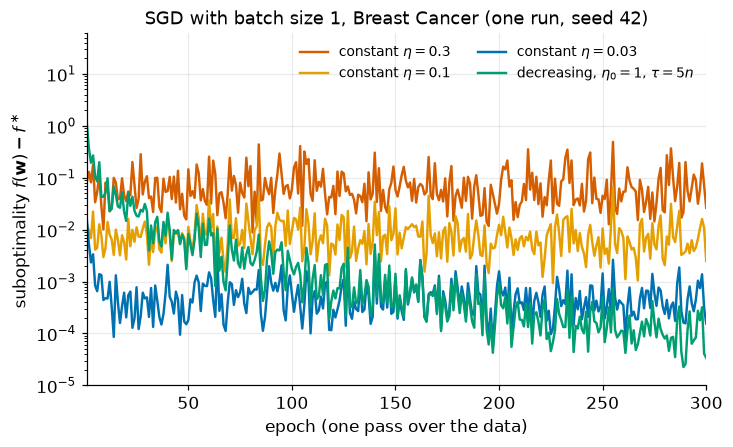

In [26]:
# Figure 7.8 — constant steps hover at a noise floor; a decreasing step converges
def figure_7_8():
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ep = np.arange(1, EPOCHS + 1)
    for key, color, label in [("constant eta = 0.3", VERMILION, r"constant $\eta = 0.3$"),
                              ("constant eta = 0.1", ORANGE, r"constant $\eta = 0.1$"),
                              ("constant eta = 0.03", BLUE, r"constant $\eta = 0.03$"),
                              ("decreasing, eta_0 = 1.0, tau = 2130", GREEN, r"decreasing, $\eta_0 = 1$, $\tau = 5n$")]:
        ax.plot(ep, runs_sgd[key], color=color, lw=1.6, label=label)
    ax.set(yscale="log", xlabel="epoch (one pass over the data)", ylabel=r"suboptimality $f(\mathbf{w}) - f^\ast$",
           title="SGD with batch size 1, Breast Cancer (one run, seed 42)", xlim=(1, EPOCHS), ylim=(1e-5, 60))
    ax.legend(frameon=False, fontsize=9, loc="upper right", ncol=2)
    fig.tight_layout()
    plt.show()


figure_7_8()

Four observations, each of which is a statement of the theory.

1. **A constant step has a noise floor, and the floor falls with the step.** After the transient, the suboptimality of the constant-step runs fluctuates around a level that depends on $\eta$: $8.3 \cdot 10^{-2}$ for $\eta = 0.3$, $8.6 \cdot 10^{-3}$ for $\eta = 0.1$ and $5.3 \cdot 10^{-4}$ for $\eta = 0.03$ (the mean over epochs 251 to 300 of this single run; each epoch's value is itself random, which is why the figure is so jagged). The floor falls *faster* than proportionally to $\eta$, which does not contradict Theorem 7.11: the theorem is an upper bound that uses the worst-case variance $\sigma^2$, while the actual per-example variance decreases as the iterate approaches the minimizer (Section 7.6.1). The step $\eta = 1$ is above the range $\eta \le 1/L_{\text{glob}} = 0.30$ of the theorem and gives a floor of $0.55$: it does not diverge, but it is useless.
2. **A decreasing step converges, but starts slower.** With $\eta_k = 1/(1 + k/2130)$ the suboptimality is $5.1 \cdot 10^{-2}$ at epoch 10, when the best constant step already has $4.8 \cdot 10^{-4}$, and it keeps decreasing to $3.4 \cdot 10^{-5}$ at epoch 300 (mean over the last 50 epochs: $1.4 \cdot 10^{-4}$), below the floor of every constant step in the table. The crossover occurs after about 200 epochs. This is the usual compromise: a large step to move fast at the beginning, a small one to settle at the end.
3. **Averaging the iterates lowers the floor but does not remove it.** For the constant step $0.3$ the average of all the iterates has a suboptimality of $1.3 \cdot 10^{-2}$, six times lower than the last iterate ($8.3 \cdot 10^{-2}$), and it plateaus there. In practice one averages only the last part of the run ("tail averaging") or combines averaging with a smaller step.
4. **On this small problem SGD is not competitive.** Full-batch gradient descent with the tuned step $\eta = 8$ reaches a suboptimality of $10^{-8}$ in 69 epochs (Section 7.3.4), and SGD has not reached $10^{-4}$ after 300. With $n = 426$ examples and a well-conditioned loss ($\kappa_{\text{loc}} = 24$) a full gradient is cheap and the extra iterations of SGD buy nothing; SGD pays off when $n$ is large (we measure this on Digits in Section 7.7.1), when moderate accuracy suffices, and when the data do not fit in memory.

The batch size controls the noise. By Proposition 7.10 and Theorem 7.11 the floor is proportional to $\eta/B$, so multiplying $B$ and $\eta$ by the same factor should leave it unchanged (the *linear scaling rule*), while a larger batch at a fixed step should lower it. The next cell tests both statements with six runs, ordered by $\eta/B$.

In [27]:
rows = []
for B, eta in [(64, 0.1), (64, 0.8), (8, 0.1), (1, 0.0125), (1, 0.1), (8, 0.8)]:
    with np.errstate(all="ignore"):
        gaps = sgd_logistic(B, eta, EPOCHS)
    rows.append({"batch": B, "eta": eta, "eta / B": eta / B, "epoch 10": gaps[9], "epoch 50": gaps[49],
                 "epoch 300": gaps[299], "mean of epochs 251-300": gaps[250:].mean()})
batch_table = pd.DataFrame(rows).sort_values("eta / B")
print(batch_table.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

 batch    eta  eta / B  epoch 10  epoch 50  epoch 300  mean of epochs 251-300
    64    0.1  0.00156    0.0287   0.00298   1.13e-05                1.74e-05
    64    0.8   0.0125   0.00119  4.79e-05   4.96e-05                0.000145
     8    0.1   0.0125   0.00137  3.74e-05   1.95e-05                0.000312
     1 0.0125   0.0125   0.00126  2.97e-05   1.65e-05                5.07e-05
     1    0.1      0.1   0.00445    0.0113    0.00247                 0.00858
     8    0.8      0.1   0.00913     0.011    0.00271                  0.0381


At a fixed step $\eta = 0.1$ the floor falls with the batch size (about $9 \cdot 10^{-3}$, $3 \cdot 10^{-4}$, $2 \cdot 10^{-5}$ for $B = 1, 8, 64$), but the early progress per epoch is *slower* for large batches, since an epoch contains fewer updates ($4.5 \cdot 10^{-3}$ at epoch 10 for $B = 1$ against $2.9 \cdot 10^{-2}$ for $B = 64$). The floors are ordered like $\eta/B$, as the theory predicts, and the three runs with $\eta/B = 0.0125$ have floors of the same order of magnitude ($5 \cdot 10^{-5}$, $3 \cdot 10^{-4}$, $1.5 \cdot 10^{-4}$), although not equal: the rule is a rule of thumb that follows from an upper bound. In wall-clock time, on hardware that evaluates a batch of $B$ examples in parallel (a GPU), a larger batch costs little more than a small one, which is the practical reason for the scaling rule; our sequential NumPy loops do not show this effect.

## 7.7 SGD in practice

### 7.7.1 Choosing the learning rate

Theory tells us that the step size must be below a ceiling of order $1/L$ and that the best value is a compromise between speed and noise; it does not tell us the number, because $L$ is unknown and the useful constants are local. The practical recipe is a **grid search on a logarithmic scale**: run each candidate for a short, fixed budget (a few epochs), compare the *training objective* (the quantity being optimized, not the validation score), and keep the best, which is typically the largest value that does not diverge or oscillate. Schedules refine the picture: a **constant** step followed by a **decay** (a drop by a factor of 10 when progress stalls, a smooth cosine decay, or the $1/(1 + k/\tau)$ of Theorem 7.12), and often a short **warm-up** (a linear increase of the step over the first iterations) when the early gradients are large.

We run the experiment on the multi-class problem of Section 6.6: softmax regression on Digits (1,347 training images, 64 standardized pixels, ten classes, $\lambda = 1/(Cn)$ with $C = 3.16$, the value chosen by cross-validation in Chapter 6). The loss is smooth and strongly convex, the number of parameters is $650$, and $n$ is three times larger than for Breast Cancer. As before we compute the exact minimum $f^\ast$ first (with L-BFGS), and we use the global smoothness bound $L = \sigma_{\max}^2/(2n) + \lambda$ (the softmax Hessian is bounded by $\frac12$ of the feature Gram matrix) to express the step sizes as multiples of $1/L$.

In [28]:
dg = load_digits()
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(dg.data, dg.target, test_size=0.25, random_state=SEED, stratify=dg.target)
scaler_g = StandardScaler().fit(Xg_tr)
Zg, Zg_te = scaler_g.transform(Xg_tr), scaler_g.transform(Xg_te)
n_g, d_g = Zg.shape
K_g = 10
Yg = np.eye(K_g)[yg_tr]
lam_g = 1 / (3.16 * n_g)                       # C = 3.16, as chosen by cross-validation in Chapter 6
print(f"Digits: {n_g} training images, {d_g} pixels, {K_g} classes, lambda = {lam_g:.2e}")


def softmax_obj(w, idx=None):
    """Mean cross-entropy + (lam/2)||W||^2 (intercepts not penalized) and its gradient; w = (W.ravel(), b)."""
    W, b = w[:K_g * d_g].reshape(K_g, d_g), w[K_g * d_g:]
    A, Y = (Zg, Yg) if idx is None else (Zg[idx], Yg[idx])
    S = A @ W.T + b
    logp = S - logsumexp(S, axis=1, keepdims=True)
    P = np.exp(logp)
    f = -np.mean(np.sum(Y * logp, axis=1)) + 0.5 * lam_g * np.sum(W**2)
    gW = (P - Y).T @ A / len(A) + lam_g * W
    gb = (P - Y).mean(axis=0)
    return f, np.r_[gW.ravel(), gb]


w0_g = np.zeros(K_g * d_g + K_g)
g_chk = np.random.default_rng(SEED).normal(size=w0_g.size) * 0.1
print(f"relative error of the analytic gradient: "
      f"{np.linalg.norm(softmax_obj(g_chk)[1] - central_difference(lambda w: softmax_obj(w)[0], g_chk)) / np.linalg.norm(softmax_obj(g_chk)[1]):.1e}")

res_g = minimize(softmax_obj, w0_g, jac=True, method="L-BFGS-B", options={"maxiter": 5000, "gtol": 1e-12, "ftol": 1e-16})
f_star_g, w_star_g = res_g.fun, res_g.x
L_g = np.linalg.eigvalsh(Zg.T @ Zg / n_g)[-1] / 2 + lam_g
accuracy_g = lambda w: np.mean((Zg_te @ w[:K_g * d_g].reshape(K_g, d_g).T + w[K_g * d_g:]).argmax(axis=1) == yg_te)
print(f"f* = {f_star_g:.8f} (L-BFGS, {res_g.nit} iterations), L = {L_g:.3f}, test accuracy of the exact minimizer: {accuracy_g(w_star_g):.4f}")

Digits: 1347 training images, 64 pixels, 10 classes, lambda = 2.35e-04


relative error of the analytic gradient: 2.8e-09
f* = 0.03371726 (L-BFGS, 212 iterations), L = 3.635, test accuracy of the exact minimizer: 0.9733


In [29]:
grid = [0.03, 0.1, 0.3, 1, 3, 10, 30, 100]                 # step sizes, in units of 1/L
configs = {"full batch (GD)": n_g, "batch 128": 128, "batch 16": 16, "batch 1": 1}
EPOCHS_G = 30
results_g = {}
t0 = time.time()
for name, B in configs.items():
    for etaL in grid:
        with np.errstate(all="ignore"):
            results_g[(name, etaL)] = sgd(softmax_obj, w0_g, n_g, B, etaL / L_g, EPOCHS_G, f_star_g)
print(f"{len(results_g)} runs of {EPOCHS_G} epochs in {time.time() - t0:.0f} s")

best_g, rows = {}, []
for name in configs:
    cands = [(results_g[(name, e)][0][-1], e) for e in grid if np.isfinite(results_g[(name, e)][0][-1])]
    _, etaL = min(cands)
    gaps, w = results_g[(name, etaL)]
    best_g[name] = etaL
    rows.append({"method": name, "best eta*L": etaL, **{f"gap, epoch {e}": gaps[e - 1] for e in (1, 5, 10, 30)},
                 "test accuracy": accuracy_g(w)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

32 runs of 30 epochs in 30 s
         method  best eta*L  gap, epoch 1  gap, epoch 5  gap, epoch 10  gap, epoch 30  test accuracy
full batch (GD)          30          0.64         0.109         0.0501         0.0149          0.956
      batch 128          10         0.116        0.0334         0.0151        0.00265          0.971
       batch 16           1         0.147        0.0432         0.0217        0.00437          0.971
        batch 1         0.1         0.109        0.0277         0.0114        0.00176          0.969


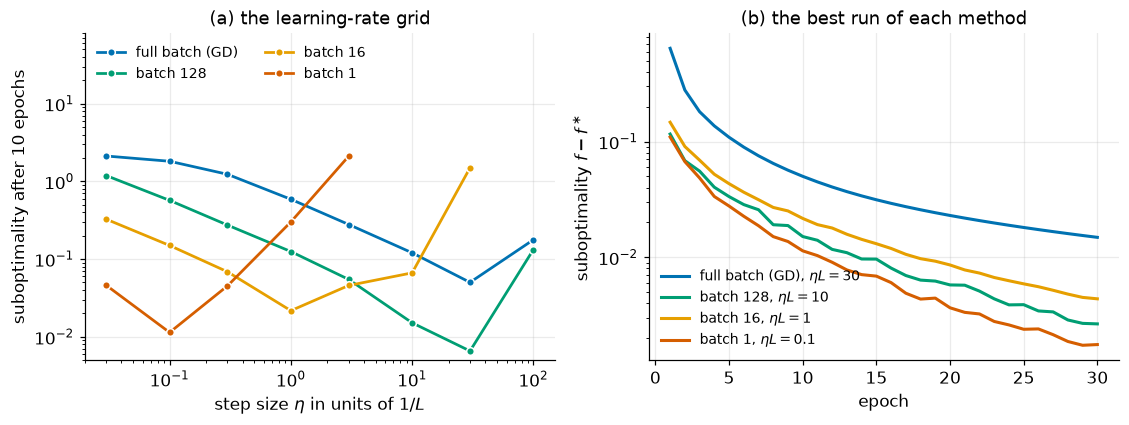

In [30]:
# Figure 7.9 — the learning-rate grid, and the best run of each method
def figure_7_9():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0))
    colors = {"full batch (GD)": BLUE, "batch 128": GREEN, "batch 16": ORANGE, "batch 1": VERMILION}
    for name, color in colors.items():
        xs, ys = [], []
        for etaL in grid:
            g10 = results_g[(name, etaL)][0][9]
            if np.isfinite(g10) and g10 < 10:
                xs.append(etaL)
                ys.append(g10)
        axes[0].plot(xs, ys, "-o", color=color, lw=1.8, ms=5, mec="white", label=name)
        gaps = results_g[(name, best_g[name])][0]
        axes[1].plot(np.arange(1, EPOCHS_G + 1), gaps, color=color, lw=2, label=f"{name}, $\\eta L = {best_g[name]}$")
    axes[0].set(xscale="log", yscale="log", xlabel=r"step size $\eta$ in units of $1/L$", ylim=(5e-3, 80),
                ylabel=r"suboptimality after 10 epochs", title="(a) the learning-rate grid")
    axes[1].set(yscale="log", xlabel="epoch", ylabel=r"suboptimality $f - f^\ast$", title="(b) the best run of each method")
    axes[0].legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
    axes[1].legend(frameon=False, fontsize=9, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_7_9()

Three facts stand out. First, each method has a U-shaped curve in $\eta$: too small a step makes no progress in 10 epochs, too large a step makes the iteration unstable and the points of the grid that diverged are missing from the plot. Second, the best step grows with the batch size, from $0.1/L$ for pure SGD through $1/L$ and $10/L$ for batches of 16 and 128 to $30/L$ for full-batch gradient descent, roughly in proportion to $B$ (the scaling rule of Section 7.6.3); for the large batches these values are far *above* the $1/L$ of the theory, because $L$ is the global bound and the curvature near the solution is smaller. Third, with the best step of each, the stochastic methods are ahead of full-batch GD *per epoch*: after 30 epochs the suboptimality is $0.0149$ for GD and between $0.0018$ and $0.0044$ for SGD, and the test accuracies of the stochastic methods ($0.969$ to $0.971$) are as close to that of the exact minimizer ($0.973$) as the evaluation on 450 images can resolve, while GD's final iterate is a little behind ($0.956$). That is the regime in which SGD is worth using (compare with Breast Cancer, where $n$ is small and the problem well conditioned): each epoch of SGD performs $n/B$ updates instead of one, and the early iterations, when the gradient is large compared with the noise, are almost as good as full gradients at a fraction of the cost. L-BFGS needs $209$ iterations to reach the exact minimum, that is $209$ full gradients, more than the $30$ epochs after which SGD is already within a suboptimality of $0.002$ to $0.004$.

### 7.7.2 Early stopping is implicit ridge regression

An iterative optimizer is a path in parameter space, and the model that we use is the point at which we stop. For gradient descent started at $\mathbf{w}_0 = \mathbf{0}$ on a least-squares problem, Theorem 7.3 describes that path exactly, and it is *the same family of solutions as the ridge path of Section 6.3.2*.

:::{admonition} Proposition 7.13 (gradient descent as a spectral filter)
:class: tip
Let $\mathbf{H} = \frac1n\mathbf{X}^\top\mathbf{X} = \mathbf{V}\,\mathrm{diag}(h_j)\,\mathbf{V}^\top \succ 0$, let $\hat{\mathbf{w}}$ be the least-squares solution, and let gradient descent with $0 < \eta \le 1/L$ start from $\mathbf{w}_0 = \mathbf{0}$. Then
$$
\mathbf{w}_k = \mathbf{V}\,\mathrm{diag}\big(\varphi_j(k)\big)\,\mathbf{V}^\top\hat{\mathbf{w}},
\qquad \varphi_j(k) = 1 - (1 - \eta h_j)^k,
$$
whereas the ridge estimator with penalty $\lambda$ (the objective $\frac1{2n}\lVert\mathbf{y} - \mathbf{X}\mathbf{w}\rVert^2 + \frac\lambda2\lVert\mathbf{w}\rVert^2$) is $\hat{\mathbf{w}}_\lambda = \mathbf{V}\,\mathrm{diag}\big(r_j(\lambda)\big)\mathbf{V}^\top\hat{\mathbf{w}}$ with $r_j(\lambda) = h_j/(h_j + \lambda)$. If $\lambda = 1/(\eta k)$, then for every direction $j$
$$
r_j(\lambda) \le \varphi_j(k) \le 2\,r_j(\lambda).
$$
Both filters keep the directions of large $h_j$ (large curvature, where the data are informative) and suppress those of small $h_j$; the number of steps plays the role of $1/\lambda$.
:::

:::{admonition} Proof
:class: dropdown
The first formula is Theorem 7.3 with $\mathbf{w}_0 = \mathbf{0}$ ($\mathbf{w}_0 - \mathbf{w}^\ast = -\hat{\mathbf{w}}$), the second is the ridge formula of Section 6.3.2. Put $x = \eta h_j \in (0, 1]$ and $t = kx = h_j/\lambda$, so that $r_j = t/(1 + t)$. *Lower bound:* $(1 - x)^k \le e^{-kx} = e^{-t} \le 1/(1 + t)$, hence $\varphi_j = 1 - (1 - x)^k \ge 1 - 1/(1 + t) = t/(1 + t)$. *Upper bound:* by Bernoulli's inequality $(1 - x)^k \ge 1 - kx$, so $\varphi_j \le \min\{1, t\}$; and $\min\{1, t\} \le 2t/(1 + t)$ (for $t \le 1$ because $1 + t \le 2$, for $t \ge 1$ because $2t/(1 + t) \ge 1$). $\square$
:::

The sandwich is not an equality, so early-stopped GD is not *exactly* a ridge estimator, but it is within a factor $2$ in every direction, and the two paths are very close in practice. We verify it on the Diabetes problem of Section 7.3.2: along the gradient-descent path (with $\eta = 1/L$) and along the ridge path with $\lambda = 1/(\eta k)$ we compute the exact solution after $k$ steps (by the formula, which is exact for a quadratic) and the test error on the 111 held-out patients.

In [31]:
h_d, V_d = np.linalg.eigh(H_d)
a_d = V_d.T @ w_star_d                                       # least-squares solution in the eigenbasis
eta_es = 1 / L_d


def w_gd(k):
    return V_d @ ((1 - (1 - eta_es * h_d) ** k) * a_d)


def w_ridge(lam):
    return V_d @ (h_d / (h_d + lam) * a_d)


test_mse = lambda w: np.mean((yd_te - yd_mean - Zd_te @ w) ** 2)
ks_es = np.unique(np.round(np.logspace(0, 5, 120)).astype(np.int64))
mse_gd = np.array([test_mse(w_gd(k)) for k in ks_es])
mse_rd = np.array([test_mse(w_ridge(1 / (eta_es * k))) for k in ks_es])
mse_ols = test_mse(w_star_d)
i_gd, i_rd = mse_gd.argmin(), mse_rd.argmin()
print(f"least squares (the end of both paths): test MSE {mse_ols:.1f}")
print(f"best early-stopped GD: k = {ks_es[i_gd]}, test MSE {mse_gd[i_gd]:.1f}")
print(f"best ridge on the same grid: lambda = 1/(eta k) = {1 / (eta_es * ks_es[i_rd]):.3f}, test MSE {mse_rd[i_rd]:.1f}")

phi = 1 - (1 - eta_es * h_d[None, :]) ** ks_es[:, None]
rr = h_d[None, :] / (h_d[None, :] + 1 / (eta_es * ks_es[:, None]))
print(f"ratio of the GD filter to the ridge filter, over all directions and all k: from {(phi / rr).min():.3f} to {(phi / rr).max():.3f} "
      f"(Proposition 7.13: between 1 and 2)")
for k in (100, 1000, 10000):
    wg, wr = w_gd(k), w_ridge(1 / (eta_es * k))
    print(f"k = {k:>5}: ||w_GD|| = {np.linalg.norm(wg):6.1f}, ||w_ridge|| = {np.linalg.norm(wr):6.1f}, "
          f"relative distance between the two = {np.linalg.norm(wg - wr) / np.linalg.norm(wr):.3f}")

least squares (the end of both paths): test MSE 2848.3
best early-stopped GD: k = 7, test MSE 2813.8
best ridge on the same grid: lambda = 1/(eta k) = 0.178, test MSE 2809.0
ratio of the GD filter to the ridge filter, over all directions and all k: from 1.000 to 2.000 (Proposition 7.13: between 1 and 2)
k =   100: ||w_GD|| =   43.3, ||w_ridge|| =   41.7, relative distance between the two = 0.045
k =  1000: ||w_GD|| =   66.3, ||w_ridge|| =   57.7, relative distance between the two = 0.201
k = 10000: ||w_GD|| =   70.5, ||w_ridge|| =   68.6, relative distance between the two = 0.033


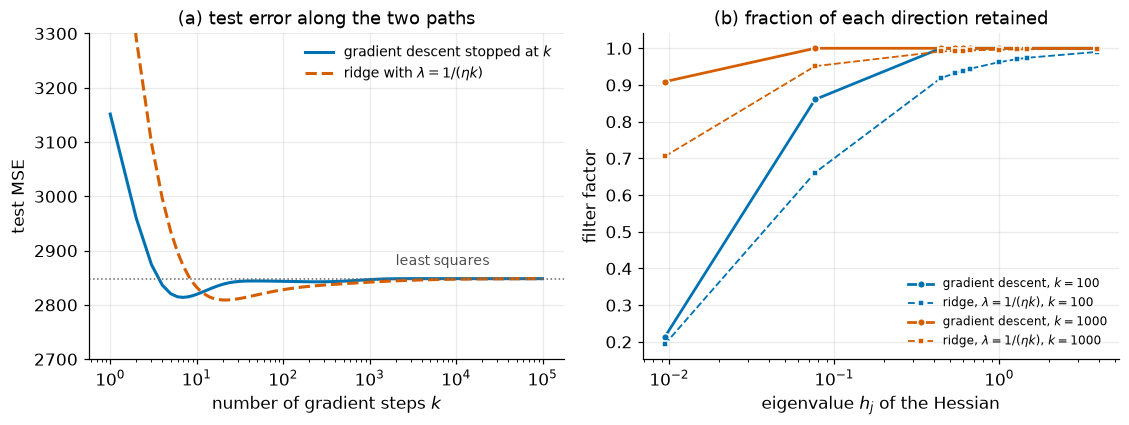

In [32]:
# Figure 7.10 — early stopping and ridge: the same path, up to a factor of two in every direction
def figure_7_10():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0))
    ax = axes[0]
    ax.plot(ks_es, mse_gd, color=BLUE, lw=2, label="gradient descent stopped at $k$")
    ax.plot(ks_es, mse_rd, color=VERMILION, lw=2, ls="--", label=r"ridge with $\lambda = 1/(\eta k)$")
    ax.axhline(mse_ols, color="0.4", lw=1, ls=":")
    ax.text(2e3, mse_ols + 25, "least squares", fontsize=9, color="0.3")
    ax.set(xscale="log", ylim=(2700, 3300), xlabel="number of gradient steps $k$",
           ylabel="test MSE", title="(a) test error along the two paths")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    ax = axes[1]
    for k, color in [(100, BLUE), (1000, VERMILION)]:
        ax.plot(h_d, 1 - (1 - eta_es * h_d) ** k, "-o", color=color, lw=1.8, ms=5, mec="white", label=f"gradient descent, $k = {k}$")
        ax.plot(h_d, h_d / (h_d + 1 / (eta_es * k)), "--s", color=color, lw=1.2, ms=4, mec="white", label=rf"ridge, $\lambda = 1/(\eta k)$, $k = {k}$")
    ax.set(xscale="log", xlabel=r"eigenvalue $h_j$ of the Hessian", ylabel="filter factor",
           title="(b) fraction of each direction retained")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    fig.tight_layout()
    plt.show()


figure_7_10()

The two test-error curves are almost the same: a minimum slightly below the least-squares error ($1.2\%$ lower for early stopping at $k = 7$, $1.4\%$ for ridge, differences of about one percent, well within the noise of an evaluation on 111 test patients: in Section 6.3.4 ridge gained 7 points out of 2848 on this very split, and nothing on average over many splits) and a return to the least-squares value as $k \to \infty$. The ratio of the two filters, computed over all ten directions and all the iteration counts of the grid, lies between $1.000$ and $2.000$: both bounds of Proposition 7.13 are attained (the upper one at $k = 1$ in the steepest direction, where gradient descent with $\eta = 1/L$ removes the whole error and ridge only half). The weights differ by $4.5\%$, $20\%$ and $3.3\%$ at $k = 100$, $10^3$ and $10^4$; the paths are the same family, not the same curve.

Early stopping regularizes *in the metric of the parametrization*, because the filter acts on the eigenvectors of the Hessian of the problem *as it is posed*. The same $k$ means different things in different units. The next cell stops gradient descent after the same numbers of iterations on the standardized and on the raw Diabetes features, from $\mathbf{w}_0 = \mathbf{0}$, again exactly by the formula of Theorem 7.3.

In [33]:
h_raw, V_raw = np.linalg.eigh(H_raw)
w_ols_raw = np.linalg.solve(H_raw, b_raw)
a_raw = V_raw.T @ w_ols_raw
eta_raw = 1 / h_raw[-1]
Xte_c = Xd_te - Xd_tr.mean(axis=0)
test_mse_raw = lambda w: np.mean((yd_te - yd_mean - Xte_c @ w) ** 2)
rows = []
for k in [1, 10, 100, 1000, 10_000, 100_000, 1_000_000]:
    w_raw_k = V_raw @ ((1 - (1 - eta_raw * h_raw) ** k) * a_raw)
    rows.append({"k": k, "test MSE, standardized": test_mse(w_gd(k)), "test MSE, raw units": test_mse_raw(w_raw_k)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.1f}"))
print(f"(least squares: {mse_ols:.1f}; the variance of the test targets around the training mean: {np.mean((yd_te - yd_mean) ** 2):.1f})")

      k  test MSE, standardized  test MSE, raw units
      1                  3151.5               4759.9
     10                  2819.4               3718.8
    100                  2843.4               3132.3
   1000                  2846.6               3049.0
  10000                  2848.3               2971.9
 100000                  2848.3               2873.6
1000000                  2848.3               2848.3
(least squares: 2848.3; the variance of the test targets around the training mean: 5607.2)


On the standardized features the path has a sweet spot around $k = 10$ (test MSE $2819$, below the least-squares $2848$) and is at the end of its journey after $10^3$ steps. In raw units the path is monotone and *never* beats least squares: its test error falls from $4760$ after one step to $3049$ after a thousand ($7\%$ above least squares) and only reaches $2848$ after about a million steps. Here early stopping *hurts*, because the filter shrinks the directions that have small variance *in the raw units*, which are not the directions where the data are uninformative. The raw problem is not "more regularized"; it is regularized in the wrong geometry. This is one more reason to standardize (Section 7.4), and a warning that a number of epochs found for one parametrization does not transfer to another.

### 7.7.3 Gradient descent chooses the maximum-margin classifier

Section 6.4.4 left an open question: on separable data the logistic regression without a penalty has no minimizer, the weights diverge, and "the unpenalized fit is determined by the stopping rule". We can now say what the stopping rule does. Take labels $y_i \in \{-1, +1\}$, features $\tilde{\mathbf{x}}_i$ (with a constant coordinate for the intercept), and suppose that some $\mathbf{w}$ has $y_i\mathbf{w}^\top\tilde{\mathbf{x}}_i > 0$ for all $i$. The **hard-margin direction** is the solution of
$$
\hat{\mathbf{w}} = \arg\min_{\mathbf{w}}\ \lVert\mathbf{w}\rVert \quad\text{subject to}\quad y_i\,\mathbf{w}^\top\tilde{\mathbf{x}}_i \ge 1\ \text{ for all } i,
$$
the separating hyperplane with the largest margin, the object of Chapter 8.

:::{admonition} Theorem 7.14 (implicit bias of gradient descent; Soudry et al., 2018; stated without proof)
:class: tip
For linearly separable data, gradient descent on the unpenalized logistic loss with a constant step $\eta < 2/L$, from any starting point, satisfies $f(\mathbf{w}_k) \to 0$, $\lVert\mathbf{w}_k\rVert \to \infty$, and
$$
\frac{\mathbf{w}_k}{\lVert\mathbf{w}_k\rVert} \longrightarrow \frac{\hat{\mathbf{w}}}{\lVert\hat{\mathbf{w}}\rVert},
\qquad
\mathbf{w}_k = \hat{\mathbf{w}}\,\ln k + \boldsymbol\rho_k,
$$
where the correction $\boldsymbol\rho_k$ grows much more slowly than $\ln k$ (it is bounded when the support vectors span the data). The direction converges only at the rate $O(1/\ln k)$.
:::

In words: the logistic loss decreases forever by growing the weights, the *size* of $\mathbf{w}_k$ is set by the number of iterations (logarithmically), and the *direction* converges, among all the separating directions, to the one with the largest margin. Early stopping then chooses a size, hence how confident the probabilities are, while the direction is already that of the support vector machine. Worked example 7.2 was the one-dimensional case: $w_k$ grows like $\log k$.

We check the theorem on the two Iris classes of Section 6.4.4 (setosa against versicolor, petal length and width, standardized), which are separable. We append the constant column and compute the hard-margin direction in the augmented space with `LinearSVC` with a very large $C$, without intercept: that is the optimization problem above (we use it here as a black box, and Chapter 8 explains it). Then we run gradient descent with $\eta = 1/L$ for one million iterations and compare.

In [34]:
iris = load_iris()
mask = iris.target < 2
Zi = StandardScaler().fit_transform(iris.data[mask][:, [2, 3]])
yi = iris.target[mask].astype(float)                          # 0 = setosa, 1 = versicolor
Ai = np.c_[np.ones(len(yi)), Zi]                               # augmented features
si = 2 * yi - 1                                                # labels in {-1, +1}

svm = LinearSVC(C=1e6, loss="hinge", fit_intercept=False, dual=True, max_iter=2_000_000, tol=1e-10).fit(Ai, yi)
w_hat = svm.coef_.ravel()
margins = si * (Ai @ w_hat)
print(f"hard-margin direction (augmented space): {np.round(w_hat, 4)}, ||w_hat|| = {np.linalg.norm(w_hat):.4f}")
print(f"constraints that are active (margin = 1): examples {np.flatnonzero(margins < 1 + 1e-6)}; "
      f"largest geometric margin = 1/||w_hat|| = {1 / np.linalg.norm(w_hat):.4f}")

L_i = np.linalg.eigvalsh(Ai.T @ Ai / len(yi))[-1] / 4
w_i = np.zeros(3)
checkpoints = {10, 100, 1000, 10_000, 100_000, 1_000_000}
rows, path_i = [], []
log_ks = set(np.unique(np.round(np.logspace(0, 6, 61)).astype(int)))
for k in range(1, 1_000_001):
    w_i = w_i - (1 / L_i) * (Ai.T @ (expit(Ai @ w_i) - yi)) / len(yi)
    if k in log_ks:
        path_i.append((k, w_i.copy()))
    if k in checkpoints:
        cos = w_i @ w_hat / (np.linalg.norm(w_i) * np.linalg.norm(w_hat))
        rows.append({"k": k, "||w_k||": np.linalg.norm(w_i), "angle to w_hat (degrees)": np.degrees(np.arccos(min(1.0, cos))),
                     "geometric margin": (si * (Ai @ w_i)).min() / np.linalg.norm(w_i),
                     "training loss": np.mean(np.logaddexp(0, -si * (Ai @ w_i)))})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
norms = [r["||w_k||"] for r in rows]
print(f"increase of ||w_k|| per decade of k: {np.round(np.diff(norms), 2)}; the theorem predicts ||w_hat|| ln(10) = {np.linalg.norm(w_hat) * np.log(10):.2f}")

hard-margin direction (augmented space): [0.2847 1.0537 1.099 ], ||w_hat|| = 1.5489
constraints that are active (margin = 1): examples [43 98]; largest geometric margin = 1/||w_hat|| = 0.6456


      k  ||w_k||  angle to w_hat (degrees)  geometric margin  training loss
     10    2.768                     8.302            0.5025        0.03545
    100    4.746                     4.299            0.5731        0.00564
   1000    7.216                     2.089            0.6222      0.0007456
  10000    10.06                     2.194             0.642      8.893e-05
 100000    13.16                     2.628            0.6415      9.888e-06
1000000    16.43                     2.958            0.6399      1.049e-06
increase of ||w_k|| per decade of k: [1.98 2.47 2.84 3.1  3.26]; the theorem predicts ||w_hat|| ln(10) = 3.57


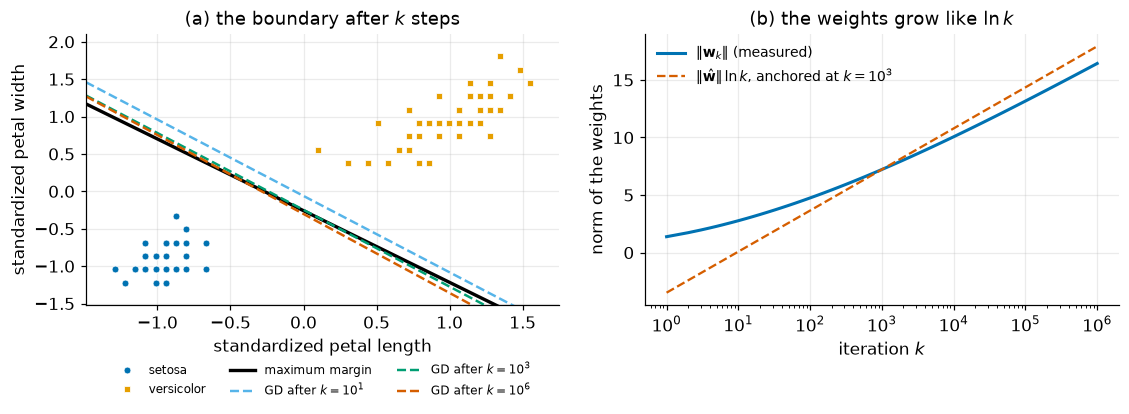

In [35]:
# Figure 7.11 — gradient descent on separable data: the decision boundary and the growth of the weights
def figure_7_11():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0))
    ax = axes[0]
    for cls, color, marker, label in [(0, BLUE, "o", "setosa"), (1, ORANGE, "s", "versicolor")]:
        ax.plot(Zi[yi == cls, 0], Zi[yi == cls, 1], marker, color=color, ms=4.5, mec="white", mew=0.5, ls="", label=label)
    x1 = np.linspace(Zi[:, 0].min() - 0.2, Zi[:, 0].max() + 0.2, 100)
    ax.plot(x1, -(w_hat[0] + w_hat[1] * x1) / w_hat[2], color="k", lw=2.2, label="maximum margin")
    for (k, wk), color in zip([p for p in path_i if p[0] in (10, 1000, 1_000_000)], [SKY, GREEN, VERMILION]):
        ax.plot(x1, -(wk[0] + wk[1] * x1) / wk[2], color=color, lw=1.6, ls="--", label=f"GD after $k = 10^{int(round(np.log10(k)))}$")
    ax.set(xlim=(x1.min(), x1.max()), ylim=(Zi[:, 1].min() - 0.3, Zi[:, 1].max() + 0.3),
           xlabel="standardized petal length", ylabel="standardized petal width", title="(a) the boundary after $k$ steps")
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
    ax = axes[1]
    kk = np.array([p[0] for p in path_i])
    nn = np.array([np.linalg.norm(p[1]) for p in path_i])
    ax.plot(kk, nn, color=BLUE, lw=2, label=r"$\|\mathbf{w}_k\|$ (measured)")
    ref = np.linalg.norm(w_hat) * np.log(kk / 1000) + nn[list(kk).index(1000)]
    ax.plot(kk, ref, color=VERMILION, lw=1.5, ls="--", label=r"$\|\hat{\mathbf{w}}\|\,\ln k$, anchored at $k = 10^3$")
    ax.set(xscale="log", xlabel="iteration $k$", ylabel=r"norm of the weights", title="(b) the weights grow like $\\ln k$")
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    fig.tight_layout()
    plt.show()


figure_7_11()

The hard-margin solution has two active constraints (two support vectors), a geometric margin of $0.646$ and a norm of $1.549$. After $10^3$ steps the gradient-descent direction is within $2.1^\circ$ of it and its margin is $96\%$ of the maximum; after $10^6$ steps the margin is $99\%$ of the maximum ($0.640$ against $0.646$). The norm of the weights grows like the theorem says: by about $2.8$, $3.1$ and $3.3$ per decade of iterations, approaching $\|\hat{\mathbf{w}}\|\ln 10 = 3.57$, while the training loss falls from $3.5 \cdot 10^{-2}$ to $10^{-6}$: the loss is already below $10^{-3}$ after a thousand steps, but the iterates keep moving, slowly, toward the max-margin direction. One detail deserves honesty: the angle is *not* monotone, it falls to $2.1^\circ$ at $k = 10^3$ and then rises slowly to $3.0^\circ$ at $k = 10^6$. The theorem guarantees convergence of the direction, with a correction $\boldsymbol\rho_k$ that is bounded only when the support vectors span the data, and here two support vectors cannot span the three-dimensional augmented space; this is consistent with a slowly growing correction, but we have not tested that explanation. The practical message is the one of the theorem: the direction converges extremely slowly (as $1/\ln k$), and nobody runs gradient descent long enough to reach it exactly, but the *region* in which early-stopped solutions lie is close to the support vector machine, and, in this experiment, very close after a thousand steps.

## 7.8 Adaptive methods: AdaGrad, RMSprop, Adam

Different coordinates of a model can have gradients of very different sizes (the raw Diabetes problem is an example), and in sparse problems some coordinates are updated rarely. **Adaptive** methods give each coordinate its own step size, built from the history of its gradients. All use the elementwise square $\mathbf{g}^2$ of the gradient.

- **AdaGrad** (Duchi, Hazan and Singer, 2011) accumulates $\mathbf{G}_k = \mathbf{G}_{k-1} + \mathbf{g}_k^2$ and moves by $-\eta\,\mathbf{g}_k/(\sqrt{\mathbf{G}_k} + \varepsilon)$: coordinates with large past gradients get small steps.
- **RMSprop** (Hinton, 2012) replaces the sum by a moving average, $\mathbf{v}_k = \rho\mathbf{v}_{k-1} + (1 - \rho)\mathbf{g}_k^2$, so that the memory is finite and the steps do not shrink to zero.
- **Adam** (Kingma and Ba, 2015) adds momentum and a correction for the zero initialization of the averages:
$$
\mathbf{m}_k = \beta_1\mathbf{m}_{k-1} + (1 - \beta_1)\mathbf{g}_k, \quad
\mathbf{v}_k = \beta_2\mathbf{v}_{k-1} + (1 - \beta_2)\mathbf{g}_k^2, \quad
\mathbf{w}_{k+1} = \mathbf{w}_k - \eta\,\frac{\mathbf{m}_k/(1 - \beta_1^k)}{\sqrt{\mathbf{v}_k/(1 - \beta_2^k)} + \varepsilon},
$$
with the usual defaults $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-8}$.

In the language of Section 7.4, these methods build a *diagonal* preconditioner from the gradient history, adapted at run time instead of fixed by the units of the features. Their step size is no longer in units of $1/L$: the coordinate-wise move has size of order $\eta$ whatever the scale of the gradient, which is why $\eta$ for Adam is typically between $10^{-4}$ and $10^{-1}$ in the units of the parameters.

The next experiment is a comparison on a deterministic problem, with full gradients, so that only the update rule matters: Diabetes least squares in raw units (where the diagonal rescaling matters most) and standardized. For AdaGrad and Adam the step size $\eta$ is chosen from a logarithmic grid by the final suboptimality after $3{,}000$ iterations, that is **with hindsight**, which is favorable to them; gradient descent uses $\eta = 1/L$. The numbers describe this problem and this tuning protocol, not a general ranking.

In [36]:
def adaptive_run(grad, record, w0, kind, eta, iters, eps=1e-8, beta1=0.9, beta2=0.999):
    w = w0.copy()
    m, v, out = np.zeros_like(w), np.zeros_like(w), np.empty(iters)
    for k in range(1, iters + 1):
        out[k - 1] = record(w)
        g = grad(w)
        if kind == "adagrad":
            v += g**2
            w = w - eta * g / (np.sqrt(v) + eps)
        else:                                                    # Adam
            m = beta1 * m + (1 - beta1) * g
            v = beta2 * v + (1 - beta2) * g**2
            w = w - eta * (m / (1 - beta1**k)) / (np.sqrt(v / (1 - beta2**k)) + eps)
    return out


ITERS_A = 3000
problems = {"raw units": (H_raw, b_raw), "standardized": (H_d, b_d)}
curves_a, rows = {}, []
for pname, (H, b) in problems.items():
    ws = np.linalg.solve(H, b)
    grad_q = lambda w, H=H, b=b: H @ w - b
    rec_q = lambda w, H=H, ws=ws: 0.5 * (w - ws) @ H @ (w - ws)
    L_q = np.linalg.eigvalsh(H)[-1]
    runs = {"gradient descent": (1 / L_q, momentum_run(grad_q, rec_q, np.zeros(10), 1 / L_q, lambda k: 0.0, ITERS_A, "hb"))}
    for kind, eta_grid in [("adagrad", [0.01, 0.03, 0.1, 0.3, 1, 3, 10]), ("adam", [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])]:
        cands = []
        for eta in eta_grid:
            c = adaptive_run(grad_q, rec_q, np.zeros(10), kind, eta, ITERS_A)
            if np.isfinite(c[-1]):
                cands.append((c[-1], eta, c))
        _, eta_best, c_best = min(cands, key=lambda t: t[0])
        runs["AdaGrad" if kind == "adagrad" else "Adam"] = (eta_best, c_best)
    curves_a[pname] = runs
    for name, (eta, c) in runs.items():
        rows.append({"problem": pname, "method": name, "eta": eta, **{f"gap, k = {k}": max(c[k - 1], 0.0) for k in (10, 100, 1000, 3000)}})
print(f"initial suboptimality: raw {curves_a['raw units']['gradient descent'][1][0]:.0f}, "
      f"standardized {curves_a['standardized']['gradient descent'][1][0]:.0f}")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
c_adam = curves_a["raw units"]["Adam"][1]
print(f"Adam on raw units: smallest value {c_adam.min():.1e}, then the largest suboptimality between k = 1200 and 3000 is {c_adam[1199:].max():.1e}")

initial suboptimality: raw 1569, standardized 1569
     problem           method      eta  gap, k = 10  gap, k = 100  gap, k = 1000  gap, k = 3000
   raw units gradient descent 0.000478          564           189            104           86.4
   raw units          AdaGrad        3          184          42.1           6.84          0.149
   raw units             Adam        3     6.75e+03          23.8       1.39e-12       8.16e-19
standardized gradient descent    0.255         19.9          9.45          0.127       8.71e-06
standardized          AdaGrad       10         23.3          8.95         0.0495       4.81e-07
standardized             Adam        1          405          12.8       0.000847       2.09e-28
Adam on raw units: smallest value 6.9e-28, then the largest suboptimality between k = 1200 and 3000 is 2.9e+03


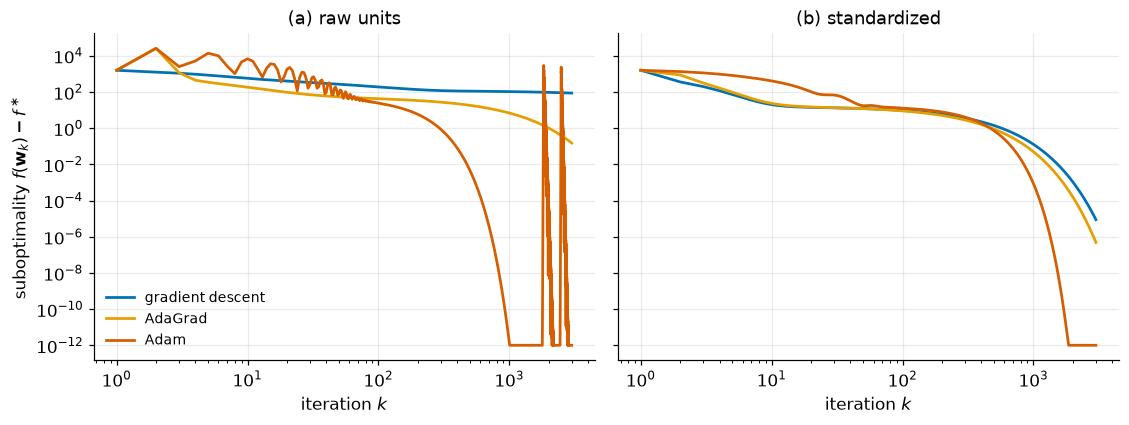

In [37]:
# Figure 7.12 — adaptive methods on the Diabetes least-squares problem
def figure_7_12():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0), sharey=True)
    for ax, pname in zip(axes, problems):
        for (name, (eta, c)), color in zip(curves_a[pname].items(), [BLUE, ORANGE, VERMILION]):
            ax.plot(np.arange(1, ITERS_A + 1), np.maximum(c, 1e-12), color=color, lw=1.8, label=name)
        ax.set(yscale="log", xscale="log", xlabel="iteration $k$", title=f"({'a' if pname == 'raw units' else 'b'}) {pname}")
    axes[0].set_ylabel(r"suboptimality $f(\mathbf{w}_k) - f^\ast$")
    axes[0].legend(frameon=False, fontsize=9, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_7_12()

On raw units, gradient descent has removed only $94\%$ of the initial suboptimality ($1569 \to 86$) after $3{,}000$ iterations, while AdaGrad reaches $0.15$ and Adam $10^{-14}$ (machine precision): the per-coordinate scaling does for the units what the standardization of Section 7.4 does by hand, since the diagonal rescaling brings $\kappa$ from $7.4 \cdot 10^4$ to $418$. On the standardized problem there is nothing left for a diagonal rescaling to fix, and gradient descent and AdaGrad are close ($8.7 \cdot 10^{-6}$ against $4.8 \cdot 10^{-7}$ at $k = 3000$); Adam is much faster at $k = 1000$ ($8.5 \cdot 10^{-4}$ against $0.13$), but note that it contains momentum, and the heavy ball of Section 7.5 is also far faster than gradient descent on this problem. Two warnings are visible in the table. Adam's first iterations *overshoot*: its suboptimality after ten iterations is $6{,}750$ on the raw problem, four times the initial value, because each coordinate moves by about $\eta$ per step whatever the size of its gradient. On the raw problem there is a second symptom: after Adam has reached machine precision (a suboptimality of $4 \cdot 10^{-28}$ at its best), the suboptimality jumps back up in isolated spikes, the largest of about $3 \cdot 10^{3}$ between $k = 1200$ and $k = 3000$, because the second-moment average of a gradient that has become tiny decays and the normalized step $\eta\hat m/\sqrt{\hat v}$ stops being small; the spikes are visible in Figure 7.12. And we tuned $\eta$ with hindsight for both adaptive methods. In the stochastic setting, where Adam is mostly used, there is no equivalent of the contraction of Theorem 7.3; Adam can fail to converge even on convex problems with a constant $\beta_2$ (Reddi, Kale and Kumar, 2018), and in practice it is run with a decaying step and a short warm-up. The rule of thumb that survives is modest: adaptive methods are less sensitive to the *scale* of the features and of the gradients, they are not a substitute for standardizing the inputs, and they do not remove the need to tune $\eta$.

## 7.9 Beyond convexity: saddles and many minima

Everything above rested on convexity: every critical point of a convex function is a global minimizer, and gradient descent finds it. The models of the next chapters are convex (support vector machines, Chapter 8, and the lasso of Chapter 10), but the neural networks of Part IV are not, and it is worth seeing now, on two small functions, what changes. *Both functions are constructed, not data.*

At a critical point $\nabla f(\mathbf{w}) = \mathbf{0}$ the eigenvalues of the Hessian tell what kind of point it is: all positive, a local minimum; all negative, a local maximum; **some positive and some negative, a saddle point**. Gradient descent is attracted to minima and repelled by maxima, but a saddle is attractive along the directions of positive curvature and repulsive along those of negative curvature, so the iteration approaches it and then, unless it is exactly on the attractive manifold, leaves along the repulsive direction. The test case is $f(x, y) = \frac{x^4}4 - \frac{x^2}2 + \frac{y^2}2$, with a saddle at the origin (Hessian $\mathrm{diag}(-1, 1)$) and two minima at $(\pm 1, 0)$ (Hessian $\mathrm{diag}(2, 1)$). Near the origin the $x$-coordinate evolves as $x_{k+1} = x_k(1 + \eta - \eta x_k^2) \approx (1 + \eta)x_k$: it grows geometrically at rate $1 + \eta\lvert\lambda_{\min}\rvert$, so starting at distance $\lvert x_0\rvert$ from the saddle the escape takes about $\ln(1/\lvert x_0\rvert)/\ln(1 + \eta)$ iterations, *plus* the time needed to cross the nonlinear region. If $x_0$ is exactly zero, however, the iteration stays on the line $x = 0$ and converges to the saddle.

In [38]:
eta_s = 0.1
rows = []
for x0 in [1e-2, 1e-6, 1e-12, 0.0]:
    p = np.array([x0, 1.0])
    hit = None
    for k in range(1, 5001):
        p = p - eta_s * np.array([p[0] ** 3 - p[0], p[1]])        # gradient of x^4/4 - x^2/2 + y^2/2
        if abs(abs(p[0]) - 1) < 1e-3:
            hit = k
            break
    est = np.log(1 / x0) / np.log(1 + eta_s) if x0 > 0 else np.inf
    rows.append({"x0": x0, "iterations to reach a minimum": hit if hit else "never (5000 run)",
                 "linearized estimate": est, "difference": (hit - est) if hit else np.nan})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print(f"at the exact saddle start, the final point after 5000 steps is {p.round(6)}")

   x0 iterations to reach a minimum  linearized estimate  difference
 0.01                            77                 48.3        28.7
1e-06                           173                  145          28
1e-12                           318                  290        28.1
    0              never (5000 run)                  inf         NaN
at the exact saddle start, the final point after 5000 steps is [0. 0.]


The measured escape times, $77$, $173$ and $318$ iterations, exceed the linearized estimates by almost the same amount ($28$ to $29$ iterations), the time of the nonlinear crossing, which does not depend on $x_0$. A starting point that is $10^{-12}$ away from the saddle needs only four times as many steps as one that is $10^{-2}$ away: a saddle is *not* a trap for gradient descent, except for the single starting point that sits exactly on its stable manifold. This is a general fact ("gradient descent almost surely avoids strict saddle points", Lee et al., 2016), and in SGD the noise of the gradient moves the iterate off the stable manifold by itself, which is one of the reasons why SGD works better than the theory of Section 7.6 would lead one to expect on non-convex problems.

The second difficulty is that there may be *several local minima*, and which one gradient descent finds depends on where it starts. The **Himmelblau function** $f(x, y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2$, a classical test function, has four minima, all with $f = 0$. We start gradient descent from every point of a $201 \times 201$ grid on $[-5, 5]^2$ and record the minimum it reaches.

In [39]:
def himmelblau_grad(P):
    x, y = P[..., 0], P[..., 1]
    return np.stack([4 * x * (x**2 + y - 11) + 2 * (x + y**2 - 7), 2 * (x**2 + y - 11) + 4 * y * (x + y**2 - 7)], axis=-1)


minima = np.array([[3.0, 2.0], [-2.805118, 3.131312], [-3.779310, -3.283186], [3.584428, -1.848126]])
print("largest gradient component at the four known minima:", np.abs(himmelblau_grad(minima)).max().round(5))
gx = np.linspace(-5, 5, 201)
P0 = np.stack(np.meshgrid(gx, gx), axis=-1).reshape(-1, 2)
P = P0.copy()
for _ in range(3000):
    P = P - 0.005 * himmelblau_grad(P)
dist = np.linalg.norm(P[:, None, :] - minima[None], axis=2)
basin = dist.argmin(axis=1)
converged = dist.min(axis=1) < 1e-2
print(f"starting points that converge to a minimum: {converged.mean():.3f}")
print("share of the starting points that reach each minimum:", np.round([(basin[converged] == i).mean() for i in range(4)], 3))

largest gradient component at the four known minima: 4e-05


starting points that converge to a minimum: 1.000
share of the starting points that reach each minimum: [0.256 0.26  0.237 0.247]


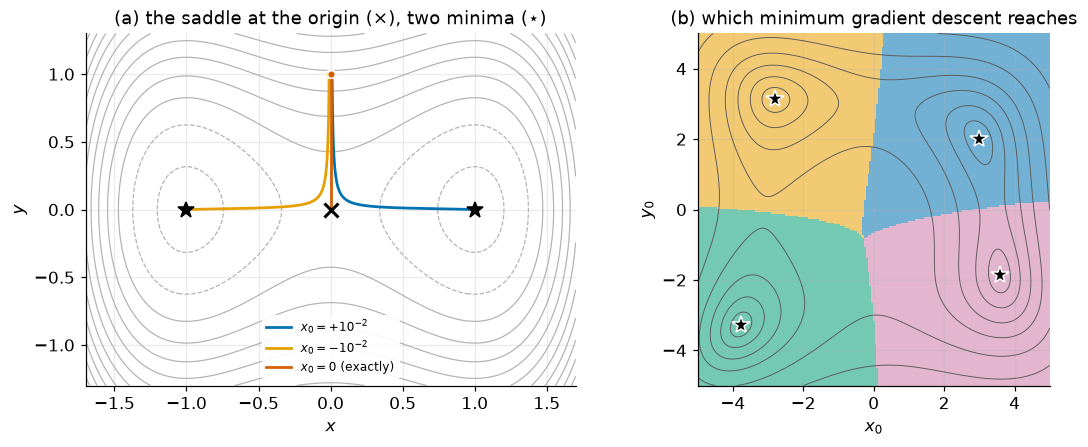

In [40]:
# Figure 7.13 — a saddle point and four basins of attraction (constructed functions)
def figure_7_13():
    from matplotlib.colors import ListedColormap
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
    ax = axes[0]
    g1, g2 = np.meshgrid(np.linspace(-1.7, 1.7, 300), np.linspace(-1.3, 1.3, 300))
    ax.contour(g1, g2, g1**4 / 4 - g1**2 / 2 + g2**2 / 2, levels=np.linspace(-0.2, 1.4, 12), colors="0.7", linewidths=0.8)
    for x0, color, lab in [(0.01, BLUE, r"$x_0 = +10^{-2}$"), (-0.01, ORANGE, r"$x_0 = -10^{-2}$"), (0.0, VERMILION, r"$x_0 = 0$ (exactly)")]:
        p = np.array([x0, 1.0])
        path = [p]
        for _ in range(160):
            p = p - eta_s * np.array([p[0] ** 3 - p[0], p[1]])
            path.append(p)
        path = np.array(path)
        ax.plot(path[:, 0], path[:, 1], "-", color=color, lw=1.8, label=lab)
        ax.plot(*path[0], "o", color=color, ms=5, mec="white")
    ax.plot([0], [0], "x", color="k", ms=9, mew=2)
    ax.plot([-1, 1], [0, 0], "*", color="k", ms=11)
    ax.set(xlabel="$x$", ylabel="$y$", title="(a) the saddle at the origin ($\\times$), two minima ($\\star$)")
    ax.legend(frameon=True, framealpha=0.9, edgecolor="none", fontsize=8, loc="lower center", ncol=1)
    ax = axes[1]
    cmap = ListedColormap([BLUE, ORANGE, GREEN, PURPLE])
    ax.imshow(basin.reshape(201, 201), origin="lower", extent=(-5, 5, -5, 5), cmap=cmap, alpha=0.55, interpolation="nearest")
    G1, G2 = np.meshgrid(gx, gx)
    ax.contour(G1, G2, (G1**2 + G2 - 11) ** 2 + (G1 + G2**2 - 7) ** 2, levels=[5, 20, 50, 100, 200, 400], colors="0.35", linewidths=0.6)
    ax.plot(minima[:, 0], minima[:, 1], "*", color="k", ms=12, mec="white")
    ax.set(xlabel="$x_0$", ylabel="$y_0$", title="(b) which minimum gradient descent reaches")
    fig.tight_layout()
    plt.show()


figure_7_13()

The four basins, each reached from about a quarter of the starting points ($25.6\%$, $26.0\%$, $23.7\%$ and $24.7\%$), are interleaved, with boundaries that wind around the saddles between the minima: a small change of the starting point can change the answer. For this function the four minima are equally good ($f = 0$), but in general they are not, and the quality of the solution then depends on the initialization and on the path: this is the reason why the random seed matters for neural networks, and why the chapters on deep networks (Chapters 14 and 15) pay so much attention to initialization.

## 7.10 Choosing an optimizer

We close the chapter by putting side by side what the experiments measured. The first table reports, for the logistic regression of Section 7.3.4 (426 examples, 31 parameters, local condition number $24$), the number of evaluations of the gradient needed to bring the suboptimality below $10^{-8}$. It is a cost in *gradients* (each is a pass over the data, of the order of $n p$ operations); Newton's method needs 7 steps, each of which also forms and solves with the Hessian.

In [41]:
cost_rows = [
    ("gradient descent, eta = 1/L_glob = 0.30", iterations_to(gd_runs["1/L_glob = 0.30"]), "no tuning, safe by the theory"),
    ("gradient descent, eta = 8.7 (largest stable constant step)", iterations_to(gd_runs["8.7"]), "needs the unknown local L"),
    ("gradient descent with backtracking", len(gaps_bt) - 1, f"plus {n_func_bt - len(gaps_bt)} extra function evaluations"),
    ("Nesterov (strongly convex version)", iterations_to(curves_b["Nesterov, strongly convex version"]), "needs mu and L"),
    ("heavy ball, beta = 0.9", iterations_to(curves_b["heavy ball, beta = 0.9"]), "beta tuned by hand"),
    ("L-BFGS", int(hist[k_lb, 1]), "memory of a few gradient pairs"),
    ("Newton", 7, "7 Hessians and 7 linear solves"),
]
print(pd.DataFrame(cost_rows, columns=["method", "gradient evaluations to gap < 1e-8", "remark"]).to_string(index=False))
print(f"SGD, batch size 1, best constant step of the grid: suboptimality after {EPOCHS} epochs "
      f"(= {EPOCHS} gradient-equivalents): {runs_sgd['constant eta = 0.03'][-1]:.1e}")

                                                    method  gradient evaluations to gap < 1e-8                              remark
                   gradient descent, eta = 1/L_glob = 0.30                                1631       no tuning, safe by the theory
gradient descent, eta = 8.7 (largest stable constant step)                                  65           needs the unknown local L
                        gradient descent with backtracking                                  57 plus 111 extra function evaluations
                        Nesterov (strongly convex version)                                 146                      needs mu and L
                                    heavy ball, beta = 0.9                                 172                  beta tuned by hand
                                                    L-BFGS                                  21      memory of a few gradient pairs
                                                    Newton                         

The same ordering is not universal: it depends on $n$, on the number of parameters $p$, on the conditioning and on the accuracy required. The guide below summarizes what the theory of this chapter and the experiments suggest.

| Method | Cost per iteration | Extra memory | Convergence (smooth convex) | Use it when |
|---|---|---|---|---|
| Gradient descent | one full gradient, $O(np)$ | none | $O(1/k)$; linear with rate $1 - 1/\kappa$ if strongly convex | the problem is small and well conditioned, or as a baseline |
| Momentum / Nesterov | one full gradient | one vector | $O(1/k^2)$; linear with $1 - 1/\sqrt\kappa$ | the problem is ill conditioned and only gradients are available |
| L-BFGS | one full gradient and a few vector products | a few gradient pairs | much faster in practice, no simple rate | smooth objective, up to millions of parameters, full data in memory (the default of `LogisticRegression`) |
| Newton | gradient, Hessian, and a solve: $O(np^2 + p^3)$ | $p^2$ | quadratic near the solution | $p$ is at most a few thousand and the Hessian is available |
| SGD (mini-batch) | $B$ per-example gradients, $O(Bp)$ | none | noise floor $\propto\eta/B$; $O(1/k)$ with decreasing step | $n$ is large or the data arrive as a stream; moderate accuracy suffices |
| AdaGrad, RMSprop, Adam | as SGD | one or two vectors | no simple guarantee in general | badly scaled coordinates, sparse gradients, neural networks |

Four rules of practice follow from the chapter. **(1)** Standardize the inputs before anything else (Section 7.4): it is the cheapest way to gain two or more orders of magnitude. **(2)** Regularization helps the optimization as well as the statistics: it adds $\lambda$ to the smallest curvature (Section 7.2.2). **(3)** For a smooth convex problem of moderate size, use a library solver (L-BFGS or Newton), which chooses its own step by line search; for large $n$, use SGD with mini-batches, a decaying step size tuned on a logarithmic grid, and monitor the *training* objective. **(4)** An iterative solver that stops at a fixed number of epochs is a regularized estimator: treat the number of iterations as a hyperparameter, to be chosen on validation data (Chapter 5), together with the other ones.

## 7.11 Summary

- **Gradient and steepest descent.** The gradients of the least-squares, logistic and softmax losses all have the form (features) $\times$ (residual) and are checked by finite differences (relative error $10^{-8}$ to $10^{-10}$). The negative gradient is the steepest descent direction (Cauchy–Schwarz); gradient descent is $\mathbf{w}_{k+1} = \mathbf{w}_k - \eta\nabla f(\mathbf{w}_k)$.
- **Curvature.** $L$-smoothness ($\nabla^2 f \preceq L\mathbf{I}$) and $\mu$-strong convexity ($\nabla^2 f \succeq \mu\mathbf{I}$) define the condition number $\kappa = L/\mu$. For least squares the eigenvalues of the Hessian are $\sigma_j^2/n + \lambda$, the singular values of Chapter 6. On Diabetes, $\kappa = 7.4 \cdot 10^4$ in raw units, $418$ standardized, $37$ with $\lambda = 0.1$ and $4.9$ with $\lambda = 1$.
- **GD on a quadratic (Theorem 7.3).** The error along the $j$-th eigenvector is multiplied by $(1 - \eta\lambda_j)$ per step: convergence iff $\eta < 2/L$, best step $2/(L + \mu)$ with rate $(\kappa - 1)/(\kappa + 1)$, at most $\kappa\ln(1/\varepsilon)$ iterations for $\eta = 1/L$. On Diabetes: $5{,}677$ iterations for $\eta = 1/L$ (predicted at most $5{,}766$), $2{,}856$ for the best step ($2{,}886$), divergence for $2.1/L$.
- **Convex and strongly convex functions.** The descent lemma gives $f(\mathbf{w}_k) - f^\ast \le \lVert\mathbf{w}_0 - \mathbf{w}^\ast\rVert^2/(2\eta k)$ (Theorem 7.4) and, with strong convexity, the contraction $\rho = \max\{\lvert 1 - \eta\mu\rvert, \lvert 1 - \eta L\rvert\}$ (Theorem 7.5). For the logistic regression on Breast Cancer the global bound $L = 3.30$ is $14$ times the curvature at the minimizer ($0.23$): $1/L$ needs $1{,}631$ iterations, $\eta = 8$ needs $69$, and the threshold of stability is $2/L_{\text{loc}} = 8.7$ (above it the iteration ends in a cycle). The $O(1/k)$ bound holds and is loose by orders of magnitude.
- **Choosing the step.** Backtracking with the Armijo condition terminates for every $L$-smooth function (Proposition 7.6): $57$ steps and $169$ function evaluations here. L-BFGS needs $19$ iterations and Newton's method $7$, at a higher cost per step.
- **Conditioning.** Rescaling the variables is preconditioning (Proposition 7.7): standardization is the Jacobi preconditioner and Newton's method the ideal one. On Diabetes it reduces the iterations needed for a thousandfold reduction of the distance from $509{,}391$ to $2{,}799$; a ridge penalty of $0.1$ reduces them to $176$.
- **Momentum.** The heavy ball has rate $(\sqrt\kappa - 1)/(\sqrt\kappa + 1)$ on quadratics (Theorem 7.8) and Nesterov's method $O(1/k^2)$ on every smooth convex function (Theorem 7.9, optimal). On Diabetes, $190$ iterations against $2{,}856$ for the best gradient descent; on the logistic regression, $146$ against $1{,}631$. Momentum methods are not descent methods.
- **SGD.** The mini-batch gradient is unbiased with variance $\sigma^2/B$, and the variance does not vanish at the minimizer ($0.27$ per example on Breast Cancer, against $5.8$ at the start). A constant step gives a noise floor of order $L\eta\sigma^2/(2\mu)$ (Theorem 7.11): on Breast Cancer $8.3 \cdot 10^{-2}$, $8.6 \cdot 10^{-3}$, $5.3 \cdot 10^{-4}$ for $\eta = 0.3, 0.1, 0.03$. A decreasing step $\eta_k = \beta/(\gamma + k)$ converges as $O(1/k)$ (Theorem 7.12): $3.4 \cdot 10^{-5}$ after 300 epochs. Averaging the iterates lowered a floor sixfold but did not remove it. The floor is ordered like $\eta/B$ (linear scaling rule). On this small problem full-batch GD (69 epochs to $10^{-8}$) is far better than SGD.
- **SGD in practice.** On Digits the best step grows with the batch size ($0.1/L$, $1/L$, $10/L$, $30/L$ for $B = 1, 16, 128, 1347$); after 30 epochs the suboptimality is $0.0149$ for full-batch GD against $0.0018$ to $0.0044$ for SGD, with test accuracies $0.956$ against $0.969$ to $0.971$ (exact minimizer: $0.973$).
- **Early stopping is implicit ridge.** GD from zero multiplies the least-squares coefficient along the $j$-th eigenvector by $1 - (1 - \eta h_j)^k$, ridge by $h_j/(h_j + \lambda)$, and with $\lambda = 1/(\eta k)$ the first is between one and two times the second (Proposition 7.13; both bounds attained). On Diabetes the test MSE falls from $2848$ to $2814$ at $k = 7$; in raw units the path is monotone and never beats least squares: early stopping regularizes in the geometry of the parametrization.
- **Implicit bias.** On separable data GD on the unpenalized logistic loss diverges in norm like $\ln k$ and its direction converges, at rate $O(1/\ln k)$, to the maximum-margin direction (Theorem 7.14). On Iris the margin is at $96\%$ of the maximum after $10^3$ steps and at $99\%$ after $10^4$, the norm grows by $3.3$ per decade at the end (theory: $3.57$) and the angle is not monotone. On Breast Cancer ($31$ parameters) the direction converges far more slowly (angle $9^\circ$ after $10^6$ steps) and the early-stopped iterates classify better than the limit (Exercise 7.10).
- **Adaptive methods** (AdaGrad, RMSprop, Adam) build a diagonal preconditioner from the gradient history. On raw Diabetes, GD still has a suboptimality of $86$ after 3,000 iterations while Adam reaches machine precision; they are less sensitive to the scale of the inputs, not a substitute for standardizing them, and their constant-step behavior has overshoots and instabilities.
- **Non-convex functions.** Saddle points repel gradient descent except from a measure-zero set: escape takes $\ln(1/\lvert x_0\rvert)/\ln(1 + \eta)$ plus a constant ($\approx 28$) iterations. With several minima the result depends on the initialization (four basins of about $25\%$ each for Himmelblau's function).

### Data sources

- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* 32(2), 407–499 (2004). Bundled with scikit-learn.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn. The target is recoded so that malignant $= 1$.
- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). The test portion of the data set, 1,797 images of $8 \times 8$ pixels, is bundled with scikit-learn.
- *Iris*: R. A. Fisher, "The use of multiple measurements in taxonomic problems", *Annals of Eugenics* 7(2), 179–188 (1936). Bundled with scikit-learn.
- *Constructed functions and data* (always flagged in the text): the quadratic $\frac12(w_1^2 + 10w_2^2)$ of Worked example 7.1, the one-parameter logistic problem of Worked example 7.2, the three-point line fit of Worked example 7.3, and the two classical test functions of Section 7.9 (the double well and the Himmelblau function, D. M. Himmelblau, *Applied Nonlinear Programming*, McGraw-Hill, 1972). All the other experiments of the chapter use the real data sets above, and the exact minima $f^\ast$ that they refer to were computed with Newton's method or L-BFGS.

### Further reading

- S. Boyd and L. Vandenberghe, *Convex Optimization*, Cambridge University Press, 2004 (free online). Chapter 9 on unconstrained minimization: gradient descent, line search, Newton's method.
- Yu. Nesterov, *Lectures on Convex Optimization*, 2nd ed., Springer, 2018. Smoothness, strong convexity, acceleration and the lower bounds.
- S. Bubeck, "Convex optimization: algorithms and complexity", *Foundations and Trends in Machine Learning* 8(3–4), 231–357 (2015). Short, complete proofs of the theorems of Sections 7.3 and 7.5, including Nesterov's.
- J. Nocedal and S. J. Wright, *Numerical Optimization*, 2nd ed., Springer, 2006. Line search, Newton and quasi-Newton methods, L-BFGS.
- L. Bottou, F. E. Curtis and J. Nocedal, "Optimization methods for large-scale machine learning", *SIAM Review* 60(2), 223–311 (2018). Theorems 7.11 and 7.12 are versions of its Theorems 4.6 and 4.7, and the paper covers variance reduction and second-order stochastic methods.
- L. Bottou and O. Bousquet, "The tradeoffs of large scale learning", *Advances in Neural Information Processing Systems* 20, 2008. Why optimization accuracy beyond the statistical error is wasted.
- H. Robbins and S. Monro, "A stochastic approximation method", *Annals of Mathematical Statistics* 22(3), 400–407 (1951). The origin of SGD.
- B. T. Polyak, "Some methods of speeding up the convergence of iteration methods", *USSR Computational Mathematics and Mathematical Physics* 4(5), 1–17 (1964). The heavy ball.
- Yu. Nesterov, "A method for solving the convex programming problem with convergence rate $O(1/k^2)$", *Soviet Mathematics Doklady* 27(2), 372–376 (1983).
- G. Goh, "Why momentum really works", *Distill* (2017). An interactive explanation of the quadratic analysis of Section 7.5.
- I. Sutskever, J. Martens, G. Dahl and G. Hinton, "On the importance of initialization and momentum in deep learning", *ICML* 2013.
- D. C. Liu and J. Nocedal, "On the limited memory BFGS method for large scale optimization", *Mathematical Programming* 45, 503–528 (1989).
- J. Duchi, E. Hazan and Y. Singer, "Adaptive subgradient methods for online learning and stochastic optimization", *Journal of Machine Learning Research* 12, 2121–2159 (2011). AdaGrad.
- T. Tieleman and G. Hinton, "Lecture 6.5 — RMSprop", *COURSERA: Neural Networks for Machine Learning*, 2012.
- D. P. Kingma and J. Ba, "Adam: a method for stochastic optimization", *ICLR* 2015, and S. J. Reddi, S. Kale and S. Kumar, "On the convergence of Adam and beyond", *ICLR* 2018.
- P. Goyal et al., "Accurate, large minibatch SGD: training ImageNet in 1 hour", arXiv:1706.02677 (2017). The linear scaling rule and warm-up.
- Y. Yao, L. Rosasco and A. Caponnetto, "On early stopping in gradient descent learning", *Constructive Approximation* 26(2), 289–315 (2007), and G. Raskutti, M. J. Wainwright and B. Yu, "Early stopping and non-parametric regression: an optimal data-dependent stopping rule", *Journal of Machine Learning Research* 15, 335–366 (2014). Early stopping as regularization.
- D. Soudry, E. Hoffer, M. S. Nacson, S. Gunasekar and N. Srebro, "The implicit bias of gradient descent on separable data", *Journal of Machine Learning Research* 19(70), 1–57 (2018). Theorem 7.14.
- J. D. Lee, M. Simchowitz, M. I. Jordan and B. Recht, "Gradient descent only converges to minimizers", *Conference on Learning Theory* (COLT) 2016. Saddle points.

## 7.12 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 7.1 ★ — Gradient descent by hand.** Let $f(\mathbf{w}) = w_1^2 + 4w_2^2$ and $\mathbf{w}_0 = (4, 1)$. (a) Compute the Hessian, $L$, $\mu$, $\kappa$ and the minimizer. (b) Run three steps of gradient descent with $\eta = 1/L$ and write the general iterate. (c) What is the best constant step size, what is the rate, and what are the first three iterates with that step? (d) For which values of $\eta$ does the iteration converge? Describe what happens for $\eta = 1/4$.

*Hint.* The Hessian is diagonal, so each coordinate is an independent one-dimensional problem: $w_{j,k+1} = (1 - \eta\lambda_j)w_{j,k}$ (Theorem 7.3).

**Exercise 7.2 ★★ — The smoothness constant of a logistic regression.** (a) Show that $\ell(m) = \log(1 + e^{-m})$ satisfies $0 < \ell''(m) \le \frac14$ and deduce that the mean logistic loss with penalty $\frac\lambda2\lVert\mathbf{w}\rVert^2$ is $L$-smooth with $L = \frac{1}{4n}\lVert\mathbf{X}\rVert_2^2 + \lambda$. (b) For the data of Exercise 6.3(a), $x = (-1, 0, 1)$ and $y = (0, 1, 1)$, with an intercept and $\lambda = 0$, compute $L$, and show that at $(b, w) = (0, 0)$ the Hessian has largest eigenvalue exactly $L$ (the bound is tight at the origin). (c) Take one step of gradient descent with $\eta = 1/L$ from $(0, 0)$, compute the new point and the values of $f$, and verify the inequality of the descent lemma (Proposition 7.2).

*Hint.* (a) $\ell'' = \sigma(m)\sigma(-m)$, and $\sigma(m)\sigma(-m) = \frac14\operatorname{sech}^2(m/2)$ or, simply, $s(1 - s) \le \frac14$ for $s \in (0, 1)$. The Hessian is $\frac1n\mathbf{X}^\top\mathrm{diag}(s_i(1 - s_i))\mathbf{X}$. (b) $\tilde{\mathbf{X}}^\top\tilde{\mathbf{X}} = \mathrm{diag}(3, 2)$. (c) The gradient at the origin is $\frac1n\tilde{\mathbf{X}}^\top(\tfrac12\mathbf{1} - \mathbf{y})$.

**Exercise 7.3 ★★ — The heavy ball on a quadratic.** Let $f$ be a quadratic with eigenvalues between $\mu = 1$ and $L = 100$. (a) What are the best step size of gradient descent, its rate, and the number of iterations needed to reduce the error by $10^{-6}$ (solve $\rho^k = 10^{-6}$)? (b) Compute the heavy-ball parameters $\eta$ and $\beta$ of Theorem 7.8, the rate, and the number of iterations from $\rho^k = 10^{-6}$. (c) For the eigenvalues $\lambda = \mu$ and $\lambda = L$, write the characteristic polynomial $z^2 - (1 + \beta - \eta\lambda)z + \beta$ and verify that it has a double root, of modulus $\sqrt\beta$.

*Hint.* $\kappa = 100$, $\sqrt\kappa = 10$. In (c), a quadratic has a double root when its discriminant vanishes.

**Exercise 7.4 ★★★ — SGD for a mean.** Let $x_0, x_1, \dots$ be independent with mean $m$ and variance $\sigma^2$ and consider the one-dimensional problem $f(w) = \frac12\mathbb{E}(w - x)^2$, with the stochastic gradient $g_k = w_k - x_k$ (so $L = \mu = 1$ and $\mathbb{E}\lVert g - \nabla f\rVert^2 = \sigma^2$). (a) With $\eta_k = 1/(k + 1)$, show that $w_k$ is the sample mean of $x_0, \dots, x_{k-1}$, so that $\mathbb{E}\,f(w_k) - f^\ast = \sigma^2/(2k)$, and compare with Theorem 7.12 (this step is the limiting case $\beta = 1/\mu$, $\gamma = 1$ of its hypothesis $\beta > 1/\mu$). (b) With a constant step $\eta \in (0, 1]$, show that $\operatorname{Var}(w_k)$ converges to $\eta\sigma^2/(2 - \eta)$, and compare $\mathbb{E}f - f^\ast = \frac12\operatorname{Var}$ with the floor $L\eta\sigma^2/(2\mu)$ of Theorem 7.11. (c) Compute both quantities for $\eta = 0.1$ and $\sigma^2 = 1$.

*Hint.* The recursion is $w_{k+1} - m = (1 - \eta_k)(w_k - m) + \eta_k(x_k - m)$. For (a), $\eta_0 = 1$ gives $w_1 = x_0$ and then $w_{k+1} = \frac{k}{k + 1}w_k + \frac1{k + 1}x_k$. For (b), the variance satisfies $V_{k+1} = (1 - \eta)^2V_k + \eta^2\sigma^2$, whose fixed point is $\eta^2\sigma^2/(1 - (1 - \eta)^2)$.

**Exercise 7.5 ★★ — Early stopping and ridge in two directions.** The Hessian of a least-squares problem is $\mathbf{H} = \mathrm{diag}(1, 0.01)$, and gradient descent with $\eta = 1$ starts from $\mathbf{w}_0 = \mathbf{0}$. (a) Write the filter factors $\varphi_j(k) = 1 - (1 - \eta h_j)^k$ of the two directions. (b) Compute the factor of the second direction for $k = 1, 10, 100, 1000$ and compare it with the ridge factor $h_2/(h_2 + \lambda)$ with $\lambda = 1/(\eta k)$. (c) What is the smallest $k$ for which the second direction is at least half recovered? Which ridge penalty gives the factor $\frac12$ exactly? (d) Verify that each ratio of (b) lies in $[1, 2]$ (Proposition 7.13).

*Hint.* For the first direction $\eta h_1 = 1$, so $\varphi_1(k) = 1$ for every $k \ge 1$. In (c) solve $0.99^k \le \frac12$. The ridge factor is $\frac12$ when $\lambda = h_2$.

### Python (computational) exercises

**Exercise 7.6 ★ — Iteration counts and the condition number.** On the standardized Diabetes training data (the split of Section 7.2.1), consider the ridge objective $\frac1{2n}\lVert\mathbf{y}_c - \mathbf{Z}\mathbf{w}\rVert^2 + \frac\lambda2\lVert\mathbf{w}\rVert^2$ for $\lambda \in \{0, 0.01, 0.1, 1\}$. (a) Check the gradient by central differences. (b) Compute $L$, $\mu$, $\kappa$ for each $\lambda$. (c) Run gradient descent with $\eta = 1/L$ from $\mathbf{w} = \mathbf{0}$ until $\lVert\mathbf{w}_k - \mathbf{w}^\ast\rVert \le 10^{-6}\lVert\mathbf{w}^\ast\rVert$, and compare the iteration counts with $\kappa\ln 10^6$. (d) Plot the number of iterations against $\kappa$ on logarithmic axes and fit the slope.

*Hint.* $\mathbf{w}^\ast = (\mathbf{Z}^\top\mathbf{Z}/n + \lambda\mathbf{I})^{-1}\mathbf{Z}^\top\mathbf{y}_c/n$. The slope of a log-log fit of "iterations" against $\kappa$ should be close to one, with an intercept depending on the weight of the starting error along the flattest direction.

**Exercise 7.7 ★★ — Line search and quasi-Newton on a non-separable problem.** On Iris, take versicolor against virginica (labels 0 and 1, all four features, standardized), with the regularized logistic loss of Section 7.3.4 ($\lambda = 0.01$, unpenalized intercept). (a) Compute $f^\ast$ with Newton's method, $L_{\text{glob}}$, and the local $L$ and $\mu$ at the minimizer. (b) Run gradient descent with $\eta = 1/L_{\text{glob}}$, with the largest constant step that converges (find it by trial between $1/L_{\text{glob}}$ and $4/L_{\text{loc}}$), with backtracking, and run L-BFGS and Newton. (c) Report the number of gradient evaluations to reach a suboptimality of $10^{-8}$ and draw the five convergence curves. Compare with the ratio $L_{\text{glob}}/L_{\text{loc}}$.

*Hint.* Reuse the structure of the code of Sections 7.3.4 and 7.3.5; the data are different, so build `Zb1`-like arrays for the new problem and write the objective with a new name.

**Exercise 7.8 ★★ — Momentum on a ridge problem.** For the standardized Diabetes data with $\lambda = 0.1$ ($\kappa = 36.7$), compare gradient descent with $\eta = 2/(L + \mu)$, the heavy ball with the parameters of Theorem 7.8 and Nesterov's strongly convex version, by the number of iterations needed to reduce $\lVert\mathbf{w}_k - \mathbf{w}^\ast\rVert/\lVert\mathbf{w}^\ast\rVert$ below $10^{-8}$. (a) Compare the ratios of iteration counts with $\sqrt\kappa$. (b) Repeat the heavy ball, keeping the step $\eta$ of Theorem 7.8, with $\beta = 0.99$ instead of the optimal value and with $\beta = 0$, and describe the trajectories (compare $\eta$ with $2/L$). (c) Plot the distance on a logarithmic axis for all the runs.

*Hint.* Use `momentum_run` of Section 7.5 with `record` equal to the relative distance to the minimizer.

**Exercise 7.9 ★★★ — The scaling rule on Digits.** With the Digits softmax problem of Section 7.7.1, run SGD for 10 epochs with batch sizes $B \in \{1, 4, 16, 64, 256\}$ and step sizes $\eta L \in \{0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300\}$ (skipping runs that diverge). (a) For each $B$, find the best $\eta L$ by the suboptimality after 10 epochs, and plot the best $\eta L$ against $B$ on logarithmic axes. (b) Fit the exponent: is the best step proportional to $B$? (c) Plot the best suboptimality against $B$ and discuss it in terms of the number of updates per epoch.

*Hint.* Use `sgd(softmax_obj, w0_g, n_g, B, etaL / L_g, 10, f_star_g)`. Define the starting point, the objective and `L_g` as in Section 7.7.1; the whole grid runs in well under a minute. A single seed cannot resolve differences of a factor of two or three between runs: say so in your discussion.

**Exercise 7.10 ★★★ — Implicit bias on Breast Cancer.** The Breast Cancer training set is linearly separable (Section 6.4.4). (a) Compute the hard-margin direction in the augmented space (standardized features and a constant column) with `LinearSVC(C=1e6, loss="hinge", fit_intercept=False, dual=True, max_iter=5_000_000, tol=1e-10)`. (b) Run gradient descent on the unpenalized logistic loss with $\eta = 1/L$ for $10^6$ iterations and, at $k = 10, 10^2, \dots, 10^6$, report $\lVert\mathbf{w}_k\rVert$, the angle to the hard-margin direction, the ratio of the geometric margin to the maximum one, and the test accuracy. (c) Compare the test accuracy of the early-stopped iterates with that of the hard-margin classifier and comment: is the implicit bias of the limit the best thing to have?

*Hint.* The margin ratio is $\min_i y_i\mathbf{w}_k^\top\tilde{\mathbf{x}}_i/\lVert\mathbf{w}_k\rVert$ divided by $1/\lVert\hat{\mathbf{w}}\rVert$, and is negative while the iterate does not yet separate the training set. The loop of $10^6$ iterations is the slowest part of the exercise. The test set has only 143 patients: do not over-interpret small differences.

## What comes next

We now have the machinery to *compute* the models of the book, and a precise understanding of what the computation does: its speed is governed by the conditioning of the problem, its noise by the batch size and the step, and stopping early is a form of regularization. **Chapter 8** studies the support vector machine, obtained by replacing the logistic loss $\log(1 + e^{-m})$ by the hinge loss $\max(0, 1 - m)$. The hinge loss is not differentiable at $m = 1$, so Theorem 7.3 and its relatives do not apply directly: the next chapter will need subgradients or the dual problem, and will show that the solution depends only on the examples near the boundary, those that Section 7.7.3 called support vectors, for which the margin bound of Section 3.8.4 is the natural guarantee. **Chapter 9** exploits the dual form of ridge regression (Proposition 6.12) to obtain kernels. **Chapter 10** replaces the $\ell_2$ penalty by the $\ell_1$ penalty, which sets coefficients exactly to zero and performs feature selection, and which is again non-differentiable, so that plain gradient descent will not be enough. **Chapter 11** returns to nonlinear models with decision trees and ensembles. In Part IV, **Chapters 14 and 15** build neural networks and **backpropagation**, which is nothing but the computation of the gradient of Section 7.2.1 for a composition of functions; the optimizers of this chapter, SGD with momentum and Adam above all, are then used on non-convex losses, with the learning-rate recipes of Section 7.7.1.